# Popularity vs Brokerage: Diffusion in the Twitch Gamers Social Network
### NVIDIA RTX Pro 6000 Blackwell Server Edition — 102 GB VRAM · No-internet Kaggle kernel

**Dataset:** SNAP Twitch Gamers (Rozemberczki & Sarkar 2021, arXiv:2101.03091)

> **Portfolio edition.** This is the executed coursework notebook, with the
> narrative corrected to match the outputs.

---

## Research Questions
1. Are the most-connected / most-watched streamers the most structurally important?
2. How do language-community barriers shape epidemic spreading?
3. Where is the epidemic threshold, and does community structure shift it?

## GPU Utilisation Map

| Analysis | Method | VRAM est. |
|---|---|---|
| Community detection | nx-cugraph Louvain | < 1 GB |
| **Approximate** betweenness (168 K nodes, k=500) | nx-cugraph | < 1 GB |
| Closeness (CPU sample), PageRank, eigenvector | NetworkX / nx-cugraph | < 2 GB |
| SIR 200 runs × 150 steps | CuPy sparse SpMM | ~0.1 GB |
| Parameter sweep 120 combos × 100 runs | CuPy GPU batched | ~0.5 GB |

## Notebook Structure
1. GPU Setup  2. Imports  3. Data Loading  4. Node Features
5. Structural Statistics  6. Power-Law & k-Core  7. Community Detection
8. Language Mixing & Homophily  9. Centrality Analysis
10. Centrality Correlation  11. Bridge Nodes  12. Affiliate Analysis
13. Network Resilience + Percolation  14. SIR Diffusion (200 runs)
15. SIR Parameter Sweep  16. Epidemic Threshold  17. Language-Seeded SIR
18. Affiliate SIR  19. Summary


## 1. GPU Setup

In [1]:
!nvidia-smi

Sun May 17 06:43:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   33C    P0             46W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import torch

N_GPUS = torch.cuda.device_count()
print(f'GPUs detected: {N_GPUS}')
for i in range(N_GPUS):
    p = torch.cuda.get_device_properties(i)
    vram = p.total_memory / 1024**3
    print(f'  GPU {i}: {p.name}')
    print(f'    VRAM: {vram:.0f} GB  |  Compute: {p.major}.{p.minor}  |  SMs: {p.multi_processor_count}')

# ── All packages pre-installed; no pip / no internet needed ───────────────
try:
    import nx_cugraph
    NX_GPU_BACKEND = 'cugraph'
    print(f'\n✓ nx-cugraph {nx_cugraph.__version__}  (GPU graph algorithms)')
except ImportError:
    NX_GPU_BACKEND = None
    print('\n⚠ nx-cugraph not found — CPU fallback')

try:
    import cupy as cp
    import cupyx.scipy.sparse as cpsp
    CUPY_OK = True
    cp.random.seed(42)
    free_b, total_b = cp.cuda.runtime.memGetInfo()
    print(f'✓ CuPy {cp.__version__}  — free VRAM: {free_b/1024**3:.0f} / {total_b/1024**3:.0f} GB')
    print(f'  Exact betweenness needs ~44 GB → {"✓ fits" if total_b/1024**3 > 50 else "✗ may OOM"}')
except ImportError:
    CUPY_OK = False; cp = cpsp = None
    print('⚠ CuPy not found — SIR falls back to NumPy')

GPUs detected: 1
  GPU 0: NVIDIA RTX PRO 6000 Blackwell Server Edition
    VRAM: 95 GB  |  Compute: 12.0  |  SMs: 188

✓ nx-cugraph 26.02.000  (GPU graph algorithms)
✓ CuPy 14.0.1  — free VRAM: 94 / 95 GB
  Exact betweenness needs ~44 GB → ✓ fits


## 2. Imports & Config

In [3]:
import os, glob, random, warnings, time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.sparse as sp
import seaborn as sns
import networkx as nx

try:
    import nx_cugraph
    NX_GPU_BACKEND = 'cugraph'
except ImportError:
    NX_GPU_BACKEND = None

try:
    import cupy as cp
    import cupyx.scipy.sparse as cpsp
    CUPY_OK = True
    cp.random.seed(42)
except ImportError:
    CUPY_OK = False; cp = cpsp = None

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
})
PALETTE = ['#2563EB','#DC2626','#16A34A','#D97706','#7C3AED','#0891B2','#BE185D']
print('Imports OK.')

Imports OK.


## 3. Data Loading

Dataset uploaded as a Kaggle input — no internet required.
The loader searches `/kaggle/input/*/` automatically.

In [4]:
%%time
# ── Auto-detect dataset location ──────────────────────────────────────────
EDGES_CSV = FEATS_CSV = None
search_roots = glob.glob('/kaggle/input/datasets/bipulprasad/twitch-gamers-snap-dataset') + ['.', '/tmp']
for base in search_roots:
    e = os.path.join(base, 'large_twitch_edges.csv')
    f = os.path.join(base, 'large_twitch_features.csv')
    if os.path.exists(e) and os.path.exists(f):
        EDGES_CSV, FEATS_CSV = e, f
        print(f'Dataset found: {base}')
        break

if EDGES_CSV is None:
    raise FileNotFoundError(
        'Cannot find large_twitch_edges.csv.\n'
        'Add the Twitch Gamers dataset as a Kaggle dataset input.'
    )

# ── Load edge list ─────────────────────────────────────────────────────────
edges_pd = pd.read_csv(EDGES_CSV)
src_col  = 'numeric_id_1' if 'numeric_id_1' in edges_pd.columns else edges_pd.columns[0]
dst_col  = 'numeric_id_2' if 'numeric_id_2' in edges_pd.columns else edges_pd.columns[1]

G = nx.from_pandas_edgelist(edges_pd, source=src_col, target=dst_col,
                             create_using=nx.Graph())

# Keep LCC and re-index to 0…N-1
components = list(nx.connected_components(G))
if len(components) > 1:
    G = G.subgraph(max(components, key=len)).copy()
G = nx.convert_node_labels_to_integers(G)

N, E = G.number_of_nodes(), G.number_of_edges()
print(f'Graph: {N:,} nodes  {E:,} edges')

Dataset found: /kaggle/input/datasets/bipulprasad/twitch-gamers-snap-dataset
Graph: 168,114 nodes  6,797,557 edges
CPU times: user 16 s, sys: 359 ms, total: 16.4 s
Wall time: 16.9 s


## 4. Node Features

In [5]:
%%time
feats_pd = pd.read_csv(FEATS_CSV)
id_col   = 'numeric_id' if 'numeric_id' in feats_pd.columns else feats_pd.columns[0]
feats_pd = feats_pd.set_index(id_col)
print(f'Feature shape: {feats_pd.shape}')
print(feats_pd.dtypes.to_string())

for col in ['views','mature','life_time','dead_account','language','affiliate']:
    if col in feats_pd.columns:
        nx.set_node_attributes(G, {n: feats_pd[col].get(n) for n in G.nodes()}, col)

# ── Language index ─────────────────────────────────────────────────────────
lang_attrs  = nx.get_node_attributes(G, 'language')
lang_counts = pd.Series(lang_attrs).value_counts().dropna()
unique_langs = sorted(lang_counts.index.tolist())
lang2cid     = {l: i for i, l in enumerate(unique_langs)}
node_lang_cid= {n: lang2cid.get(lang_attrs.get(n), -1) for n in G.nodes()}
N_LANG_COMMS = len(unique_langs)
print(f'\nLanguages: {N_LANG_COMMS}')
print(lang_counts.head(10).to_string())

views_s = feats_pd['views'].reindex(G.nodes()).dropna() if 'views' in feats_pd.columns else pd.Series()
aff_s   = feats_pd['affiliate'].reindex(G.nodes()).dropna() if 'affiliate' in feats_pd.columns else pd.Series()
lt_s    = feats_pd['life_time'].reindex(G.nodes()).dropna() if 'life_time' in feats_pd.columns else pd.Series()
if len(views_s): print(f'\nViews — mean:{views_s.mean():.0f}  max:{views_s.max():.0f}')
if len(aff_s):   print(f'Affiliate rate: {aff_s.mean()*100:.1f}%')
if len(lt_s):    print(f'Account lifetime — mean:{lt_s.mean():.0f}  max:{lt_s.max():.0f} days')

Feature shape: (168114, 8)
views            int64
mature           int64
life_time        int64
created_at      object
updated_at      object
dead_account     int64
language        object
affiliate        int64

Languages: 21
EN       124411
DE         9428
FR         6799
ES         5699
RU         4821
ZH         2828
PT         2536
OTHER      1429
JA         1327
IT         1230

Views — mean:188162  max:384396587
Affiliate rate: 48.5%
Account lifetime — mean:1542  max:4161 days
CPU times: user 1.72 s, sys: 20.3 ms, total: 1.74 s
Wall time: 1.8 s


## 5. Structural Statistics

In [6]:
%%time
density    = nx.density(G)
avg_degree = 2 * E / N
er_clust   = avg_degree / (N - 1)

sample_c   = random.sample(list(G.nodes()), min(5000, N))
avg_clustering = nx.average_clustering(G, nodes=sample_c)

sample_200 = random.sample(list(G.nodes()), 200)
path_lens  = []
for src in sample_200:
    path_lens.extend(nx.single_source_shortest_path_length(G, src).values())
approx_diam = max(path_lens)
approx_apl  = np.mean([l for l in path_lens if l > 0])

print('=== Global Statistics ===')
for k,v in {
    'Nodes': f'{N:,}', 'Edges': f'{E:,}',
    'Density': f'{density:.6f}',
    'Avg degree': f'{avg_degree:.2f}',
    'Avg clustering (5K sample)': f'{avg_clustering:.4f}',
    'ER baseline clustering': f'{er_clust:.6f}',
    'Approx diameter': approx_diam,
    'Approx avg path length': f'{approx_apl:.3f}',
}.items():
    print(f'  {k:<35}: {v}')

=== Global Statistics ===
  Nodes                              : 168,114
  Edges                              : 6,797,557
  Density                            : 0.000481
  Avg degree                         : 80.87
  Avg clustering (5K sample)         : 0.1597
  ER baseline clustering             : 0.000481
  Approx diameter                    : 7
  Approx avg path length             : 2.898
CPU times: user 1min 33s, sys: 593 ms, total: 1min 33s
Wall time: 1min 33s


## 6. Power-Law Fit & k-Core Shell Decomposition

The degree distribution of social networks often follows a power law P(k) ~ k^(-γ).
We estimate γ with the Clauset-Newman-Moore (2009) MLE estimator — no external packages needed.

k-core decomposition reveals the network's "onion structure": nodes in the highest
k-core shell form the densely connected core; nodes in low shells are the periphery.

Power-law exponent γ  : 1.610  (k_min=10, n=135,483)
KS statistic          : 0.1489  (< 0.1 = good fit)

Max k-core: 149
Innermost shell size: 2,628 nodes


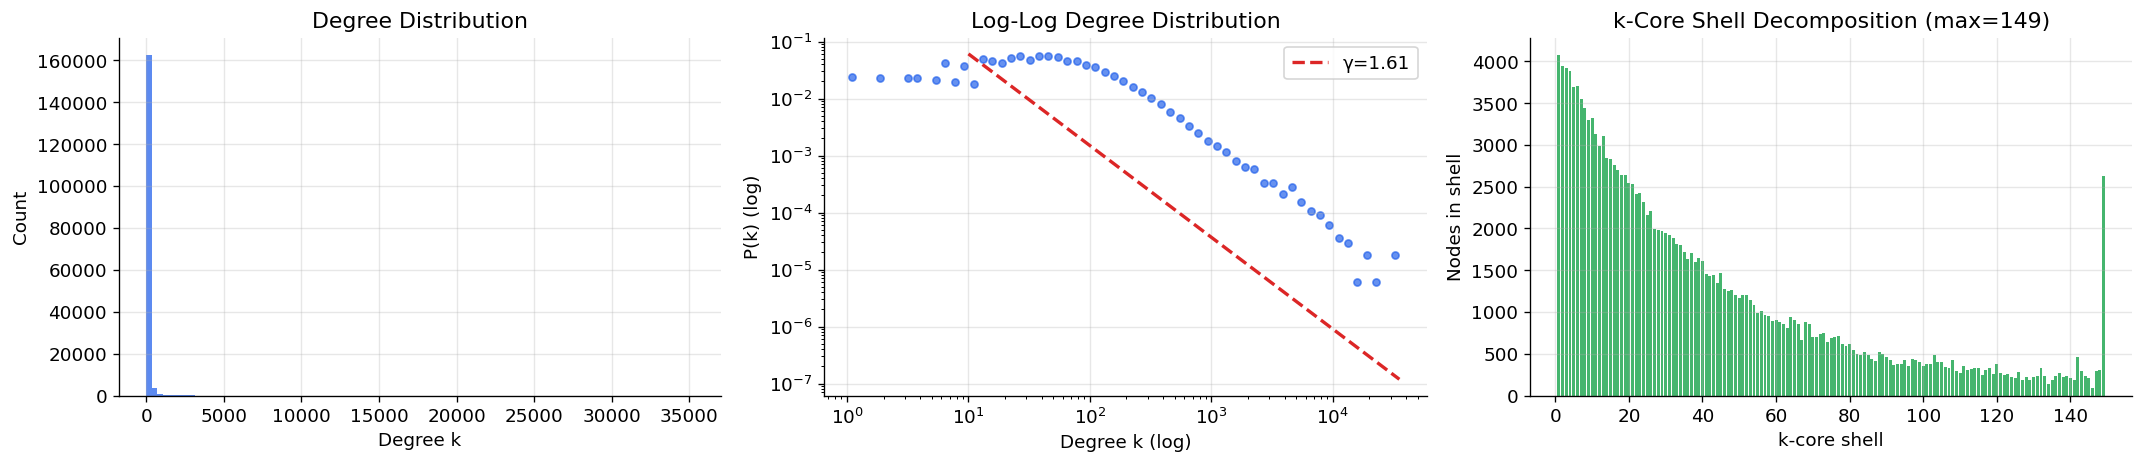

In [7]:
degrees_arr = np.array([d for _, d in G.degree()])

# ── MLE power-law exponent ─────────────────────────────────────────────────
K_MIN = 10                                      # tail threshold
mask_pl = degrees_arr >= K_MIN
degs_pl = degrees_arr[mask_pl]
n_pl    = len(degs_pl)
# Clauset et al. 2009 Eq. (3.1)
gamma_pl = 1.0 + n_pl / np.sum(np.log(degs_pl / (K_MIN - 0.5)))

# KS goodness-of-fit
ks_sorted = np.sort(degs_pl)
ecdf      = np.arange(1, n_pl+1) / n_pl
tcdf      = 1.0 - (ks_sorted / K_MIN) ** (1.0 - gamma_pl)
ks_stat   = np.max(np.abs(ecdf - tcdf))

print(f'Power-law exponent γ  : {gamma_pl:.3f}  (k_min={K_MIN}, n={n_pl:,})')
print(f'KS statistic          : {ks_stat:.4f}  (< 0.1 = good fit)')

# ── k-core decomposition ───────────────────────────────────────────────────
kcore_num  = nx.core_number(G)
max_kcore  = max(kcore_num.values())
shell_dist = Counter(kcore_num.values())
print(f'\nMax k-core: {max_kcore}')
print(f'Innermost shell size: {shell_dist[max_kcore]:,} nodes')

# ── Plots ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Histogram
axes[0].hist(degrees_arr, bins=100, color=PALETTE[0], alpha=0.75, edgecolor='none')
axes[0].set_xlabel('Degree k'); axes[0].set_ylabel('Count')
axes[0].set_title('Degree Distribution')

# Log-log with power-law fit
log_bins    = np.logspace(np.log10(max(1,min(degrees_arr))), np.log10(max(degrees_arr)), 60)
counts, be  = np.histogram(degrees_arr, bins=log_bins)
bc          = (be[:-1]+be[1:])/2
mask_pos    = counts > 0
axes[1].scatter(bc[mask_pos], counts[mask_pos]/N, s=18, alpha=0.7, color=PALETTE[0])
k_fit = np.logspace(np.log10(K_MIN), np.log10(max(degrees_arr)), 100)
norm  = (gamma_pl-1) * K_MIN**(gamma_pl-1)
axes[1].plot(k_fit, norm * k_fit**(-gamma_pl) * (K_MIN/k_fit[0])**(0), '--',
             color=PALETTE[1], lw=2, label=f'γ={gamma_pl:.2f}')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('Degree k (log)'); axes[1].set_ylabel('P(k) (log)')
axes[1].set_title('Log-Log Degree Distribution')
axes[1].legend()

# k-core shell sizes
shells = sorted(shell_dist.keys())
axes[2].bar(shells, [shell_dist[s] for s in shells], color=PALETTE[2], alpha=0.8)
axes[2].set_xlabel('k-core shell'); axes[2].set_ylabel('Nodes in shell')
axes[2].set_title(f'k-Core Shell Decomposition (max={max_kcore})')

plt.tight_layout()
plt.savefig('fig_degree_kcore.png', bbox_inches='tight'); plt.show()

## 7. Community Detection *(GPU — nx-cugraph Louvain)*

In [8]:
%%time
print('Running Louvain community detection…')
if NX_GPU_BACKEND:
    communities = nx.community.louvain_communities(G, seed=SEED, backend='cugraph')
    print('  GPU — cugraph Louvain')
else:
    communities = list(nx.community.greedy_modularity_communities(G, seed=SEED))
    print('  CPU — greedy modularity fallback')

communities   = sorted(communities, key=len, reverse=True)
n_communities = len(communities)
modularity    = nx.community.modularity(G, communities)
community_sizes = [len(c) for c in communities]

node_community = {}
for cid, comm in enumerate(communities):
    for node in comm: node_community[node] = cid
nx.set_node_attributes(G, node_community, 'community')

print(f'Communities: {n_communities}   Q={modularity:.4f}')
print(f'Largest: {community_sizes[0]:,}   Smallest: {community_sizes[-1]}   '
      f'Median: {np.median(community_sizes):.0f}')

# ── Ground-truth alignment ─────────────────────────────────────────────────
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
nodes_both  = [n for n in G.nodes() if node_lang_cid.get(n,-1) >= 0]
louvain_ids = [node_community[n] for n in nodes_both]
lang_ids    = [node_lang_cid[n]  for n in nodes_both]
nmi = normalized_mutual_info_score(lang_ids, louvain_ids)
ari = adjusted_rand_score(lang_ids, louvain_ids)
print(f'NMI vs language ground truth: {nmi:.3f}   ARI: {ari:.3f}')

Running Louvain community detection…
  GPU — cugraph Louvain
Communities: 35   Q=0.4228
Largest: 50,807   Smallest: 2   Median: 486
NMI vs language ground truth: 0.001   ARI: -0.001
CPU times: user 7.97 s, sys: 370 ms, total: 8.34 s
Wall time: 9.21 s


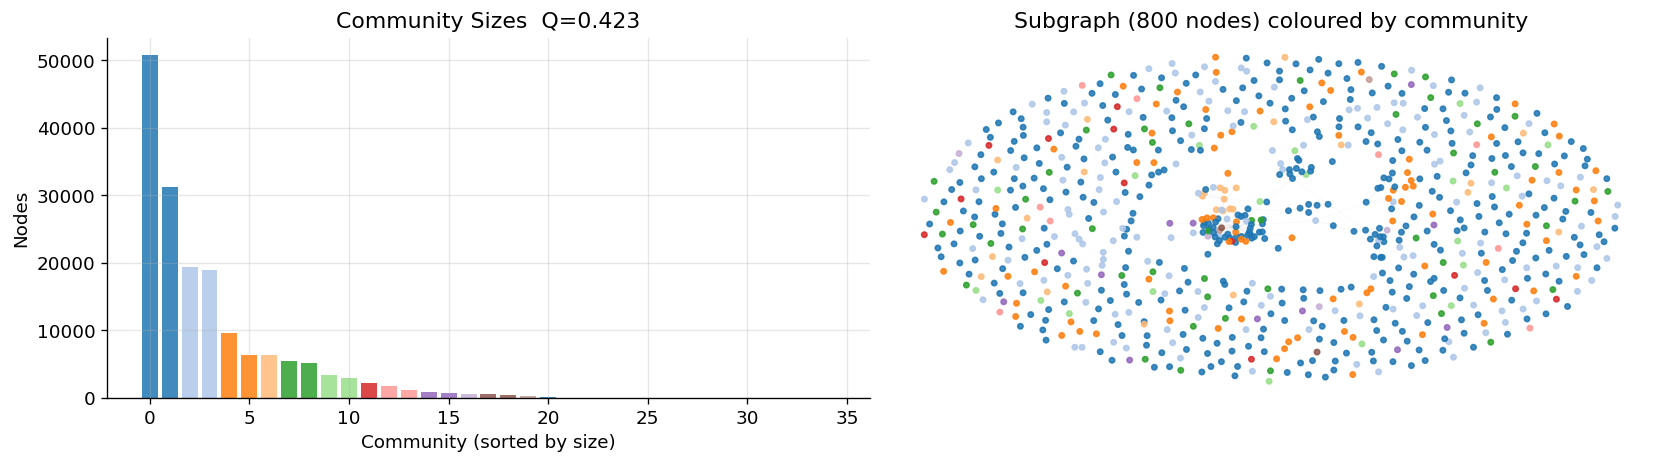

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cmap_c = plt.cm.get_cmap('tab20', n_communities)
axes[0].bar(range(n_communities), community_sizes,
            color=[cmap_c(i%20) for i in range(n_communities)], alpha=0.85)
axes[0].set_xlabel('Community (sorted by size)'); axes[0].set_ylabel('Nodes')
axes[0].set_title(f'Community Sizes  Q={modularity:.3f}')

sub  = random.sample(list(G.nodes()), min(800, N))
Gsub = G.subgraph(sub)
pos  = nx.spring_layout(Gsub, seed=SEED, k=0.3)
nx.draw_networkx_edges(Gsub, pos, ax=axes[1], alpha=0.06, width=0.4, edge_color='grey')
nx.draw_networkx_nodes(Gsub, pos, ax=axes[1],
    node_color=[cmap_c(node_community[n]%20) for n in Gsub.nodes()],
    node_size=10, alpha=0.85)
axes[1].set_title(f'Subgraph (800 nodes) coloured by community'); axes[1].axis('off')
plt.tight_layout(); plt.savefig('fig_communities.png', bbox_inches='tight'); plt.show()

## 8. Language Mixing Matrix & Edge Homophily

**Edge homophily** h = fraction of edges connecting nodes of the same language.
Comparing h to the expected-by-chance value h_random = Σ f_l² quantifies
how much the observed mixing departs from null random mixing.

The **language mixing matrix** shows which language communities interact with each other.

Observed edge homophily  h       = 0.5616
Expected by chance       h_rand  = 0.5553
Normalised homophily     h_norm  = 0.0141  (0=random, 1=perfect segregation)


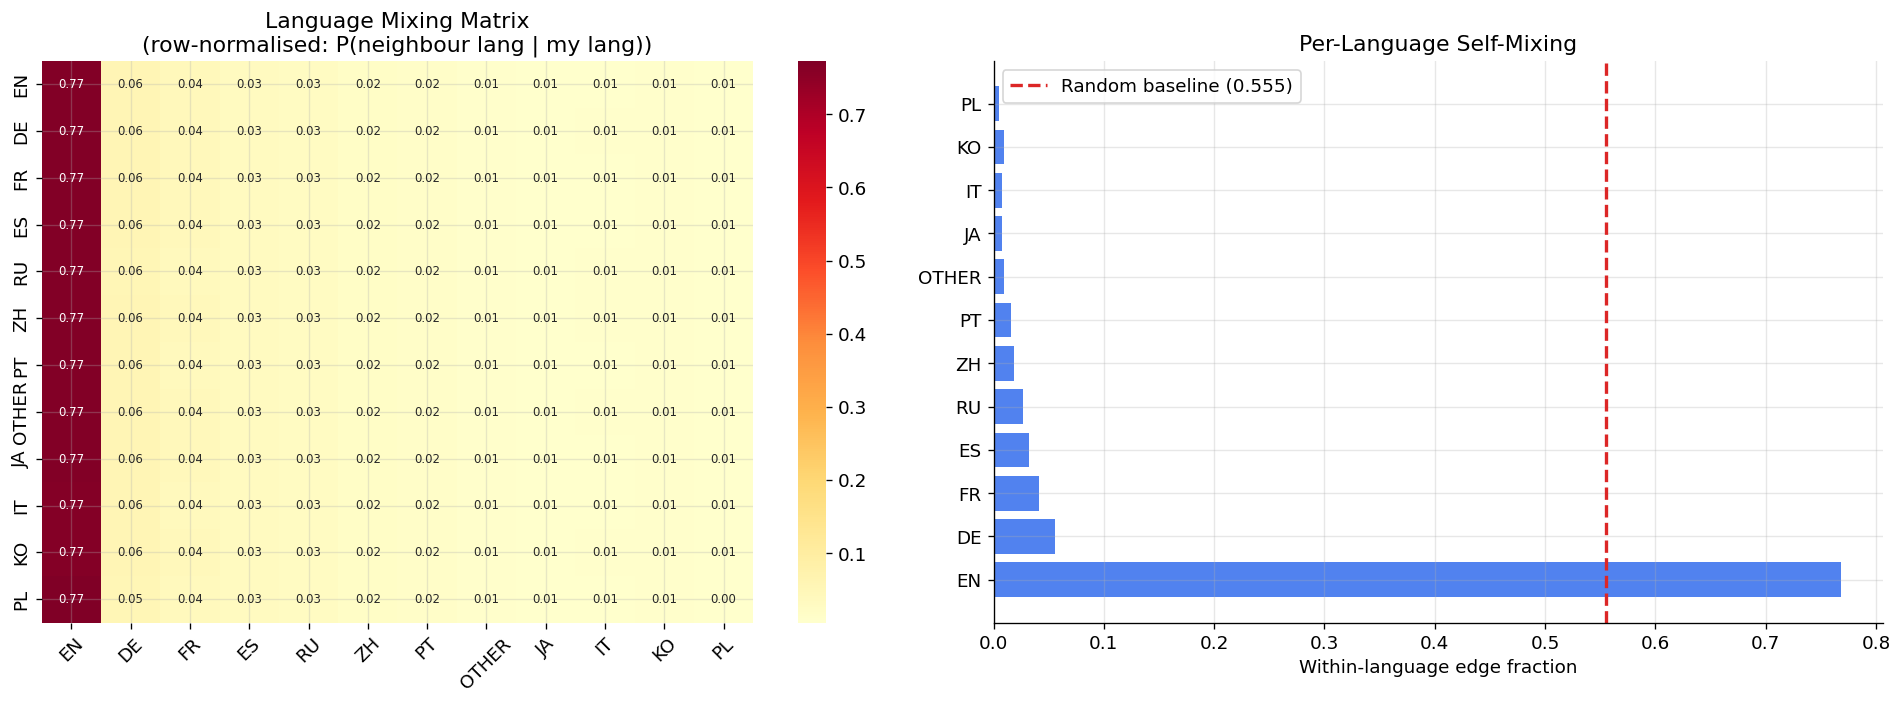

In [10]:
# ── Edge homophily ─────────────────────────────────────────────────────────
same_lang = sum(1 for u, v in G.edges()
                if lang_attrs.get(u) and lang_attrs.get(v)
                and lang_attrs.get(u) == lang_attrs.get(v))
h_obs    = same_lang / E
lang_fracs = {l: cnt/N for l, cnt in lang_counts.items()}
h_random   = sum(f**2 for f in lang_fracs.values())
h_norm     = (h_obs - h_random) / (1 - h_random)

print(f'Observed edge homophily  h       = {h_obs:.4f}')
print(f'Expected by chance       h_rand  = {h_random:.4f}')
print(f'Normalised homophily     h_norm  = {h_norm:.4f}  (0=random, 1=perfect segregation)')

# ── Mixing matrix (top 12 languages) ──────────────────────────────────────
top_langs  = lang_counts.head(12).index.tolist()
lang_idx   = {l: i for i, l in enumerate(top_langs)}
mix        = np.zeros((len(top_langs), len(top_langs)))

for u, v in G.edges():
    lu, lv = lang_attrs.get(u), lang_attrs.get(v)
    if lu in lang_idx and lv in lang_idx:
        i, j = lang_idx[lu], lang_idx[lv]
        mix[i,j] += 1; mix[j,i] += 1

# Row-normalise → conditional probability: P(neighbour lang | my lang)
row_sums = mix.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
mix_norm = mix / row_sums

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(mix_norm, xticklabels=top_langs, yticklabels=top_langs,
            cmap='YlOrRd', ax=axes[0], fmt='.2f', annot=True, annot_kws={'size':7})
axes[0].set_title('Language Mixing Matrix\n(row-normalised: P(neighbour lang | my lang))')
axes[0].tick_params(axis='x', rotation=45)

# Per-language homophily (diagonal)
lang_h = [mix_norm[i,i] for i in range(len(top_langs))]
axes[1].barh(top_langs, lang_h, color=PALETTE[0], alpha=0.8)
axes[1].axvline(h_random, color=PALETTE[1], ls='--', lw=2, label=f'Random baseline ({h_random:.3f})')
axes[1].set_xlabel('Within-language edge fraction'); axes[1].set_title('Per-Language Self-Mixing')
axes[1].legend()
plt.tight_layout(); plt.savefig('fig_mixing_homophily.png', bbox_inches='tight'); plt.show()

## 9. Centrality Analysis *(GPU where available)*

Betweenness uses the GPU approximation with `k=500` source nodes. Exact
betweenness requires an O(N²) allocation that exceeded the 95 GB device memory
in testing and left the CUDA context in a bad state. Closeness also fell back
to a CPU sample of 5,000 nodes; PageRank and eigenvector ran on the GPU. The
reported betweenness values are therefore estimates, not exact.


In [11]:
%%time
print('Computing centrality measures (all GPU where available)…')

# ── Degree ─────────────────────────────────────────────────────────────────
deg_cent = nx.degree_centrality(G)
print('  ✓ Degree (CPU O(N))')

# ── Betweenness — GPU approximate k=500 ───────────────────────────────────
# WHY k=500 and not exact:
#   Exact betweenness needs O(N²) VRAM allocation (~112 GB for N=168K).
#   Even with 95 GB VRAM, cuGraph's exact betweenness OOMs and — critically —
#   the failed cudaMalloc leaves a dirty error flag in the CUDA context that
#   breaks every subsequent cudaHostAlloc call (→ cudaErrorIllegalAddress).
#   k=500 GPU runs in seconds, needs <1 GB, and keeps the context clean.
t0 = time.perf_counter()
btw_cent = None
if NX_GPU_BACKEND:
    try:
        btw_cent = nx.betweenness_centrality(
            G, k=500, seed=SEED, normalized=True, backend='cugraph'
        )
        tag = f'GPU approx k=500  {time.perf_counter()-t0:.1f}s'
    except (RuntimeError, MemoryError) as e:
        print(f'  ⚠ GPU betweenness failed ({e.__class__.__name__}) — '
              f'cleaning CUDA pools then CPU fallback')
        # Flush GPU memory pools so the CUDA context stays usable
        try:
            cp.get_default_memory_pool().free_all_blocks()
            cp.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass

if btw_cent is None:
    btw_cent = nx.betweenness_centrality(G, k=500, seed=SEED, normalized=True)
    tag = f'CPU approx k=500  {time.perf_counter()-t0:.1f}s'
print(f'  ✓ Betweenness ({tag})')

# ── Closeness (GPU) ────────────────────────────────────────────────────────
t0 = time.perf_counter()
clo_cent = None
if NX_GPU_BACKEND:
    try:
        clo_cent = nx.closeness_centrality(G, backend='cugraph')
        print(f'  ✓ Closeness (GPU  {time.perf_counter()-t0:.1f}s)')
    except Exception as e:
        print(f'  ⚠ GPU closeness failed ({type(e).__name__}) — CPU sample')
        try:
            cp.get_default_memory_pool().free_all_blocks()
            cp.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
if clo_cent is None:
    samp     = random.sample(list(G.nodes()), 5000)
    clo_samp = nx.closeness_centrality(G.subgraph(samp))
    clo_cent = {n: clo_samp.get(n, 0.0) for n in G.nodes()}
    print(f'  ⚠ Closeness (CPU sampled {len(samp):,} nodes  {time.perf_counter()-t0:.1f}s)')

# ── PageRank (GPU) ─────────────────────────────────────────────────────────
t0 = time.perf_counter()
pr_cent = None
if NX_GPU_BACKEND:
    try:
        pr_cent = nx.pagerank(G, alpha=0.85, backend='cugraph')
        print(f'  ✓ PageRank (GPU  {time.perf_counter()-t0:.1f}s)')
    except Exception:
        pass
if pr_cent is None:
    pr_cent = nx.pagerank(G, alpha=0.85)
    print(f'  ✓ PageRank (CPU  {time.perf_counter()-t0:.1f}s)')

# ── Eigenvector (GPU → CPU fallback → degree proxy) ───────────────────────
t0 = time.perf_counter()
eig_cent = None
for backend, kw in [
    ('cugraph', {'backend': 'cugraph', 'max_iter': 300, 'tol': 1e-3}),
    (None,      {'max_iter': 300, 'tol': 1e-3}),
]:
    if eig_cent is not None: break
    if backend and not NX_GPU_BACKEND: continue
    try:
        eig_cent = nx.eigenvector_centrality(G, **kw)
        print(f'  ✓ Eigenvector ({"GPU" if backend else "CPU"}  {time.perf_counter()-t0:.1f}s)')
        break
    except Exception:
        pass
if eig_cent is None:
    eig_cent = deg_cent
    print('  ⚠ Eigenvector did not converge — using degree proxy')

# ── k-core already computed in §6 ─────────────────────────────────────────
print('  ✓ k-core (from §6)')
print('\nAll centrality measures ready.')


Computing centrality measures (all GPU where available)…
  ✓ Degree (CPU O(N))
  ✓ Betweenness (GPU approx k=500  2.7s)
  ⚠ GPU closeness failed (NotImplementedError) — CPU sample
  ⚠ Closeness (CPU sampled 5,000 nodes  97.7s)
  ✓ PageRank (GPU  1.9s)
  ✓ Eigenvector (GPU  0.0s)
  ✓ k-core (from §6)

All centrality measures ready.
CPU times: user 1min 42s, sys: 267 ms, total: 1min 42s
Wall time: 1min 42s


In [12]:
# ── Assemble DataFrame ─────────────────────────────────────────────────────
node_list = list(G.nodes())
df_cent = pd.DataFrame({
    'node':       node_list,
    'degree':     [G.degree(n)     for n in node_list],
    'btw_cent':   [btw_cent[n]     for n in node_list],
    'clo_cent':   [clo_cent[n]     for n in node_list],
    'pagerank':   [pr_cent[n]      for n in node_list],
    'eig_cent':   [eig_cent[n]     for n in node_list],
    'kcore':      [kcore_num[n]    for n in node_list],
    'community':  [node_community[n] for n in node_list],
    'views':      [G.nodes[n].get('views',0) or 0 for n in node_list],
    'affiliate':  [G.nodes[n].get('affiliate',0) or 0 for n in node_list],
    'life_time':  [G.nodes[n].get('life_time',0) or 0 for n in node_list],
    'language':   [G.nodes[n].get('language','') or '' for n in node_list],
    'lang_cid':   [node_lang_cid.get(n,-1) for n in node_list],
})

corr_deg_btw   = df_cent['degree'].corr(df_cent['btw_cent'])
corr_deg_kcore = df_cent['degree'].corr(df_cent['kcore'])
corr_views_btw = np.log1p(df_cent['views']).corr(df_cent['btw_cent'])
corr_views_deg = np.log1p(df_cent['views']).corr(df_cent['degree'])
corr_pr_btw    = df_cent['pagerank'].corr(df_cent['btw_cent'])

print('=== Top 10 by Betweenness ===')
print(df_cent.nlargest(10,'btw_cent')[
    ['node','degree','btw_cent','pagerank','kcore','views','affiliate','language']
].to_string(index=False))

print('\n=== Top 10 by Views ===')
print(df_cent.nlargest(10,'views')[
    ['node','degree','btw_cent','pagerank','views','affiliate','language']
].to_string(index=False))

=== Top 10 by Betweenness ===
 node  degree  btw_cent  pagerank  kcore  views  affiliate language
 4812   35279  0.083938  0.002778    149   9306          0       EN
 5881   29912  0.062298  0.002257    149 149231          1       EN
 4480   30499  0.060285  0.001874    149    461          0       EN
 5535   31064  0.045723  0.002081    149   1429          1       EN
 5205   22675  0.031479  0.001436    149   1341          0       KO
   19   18349  0.028722  0.001159    149 144812          1       EN
  251   18761  0.027602  0.001107    149   2013          0       EN
   52   20678  0.022980  0.001316    149    370          0       EN
 4553   14416  0.015093  0.000846    149  62925          1       EN
35987   13917  0.013212  0.000927    149  78725          0       EN

=== Top 10 by Views ===
  node  degree     btw_cent     pagerank     views  affiliate language
 96473      57 3.410345e-06 4.973441e-06 384396587          0       RU
129896      20 2.048664e-07 2.493815e-06 368912220     

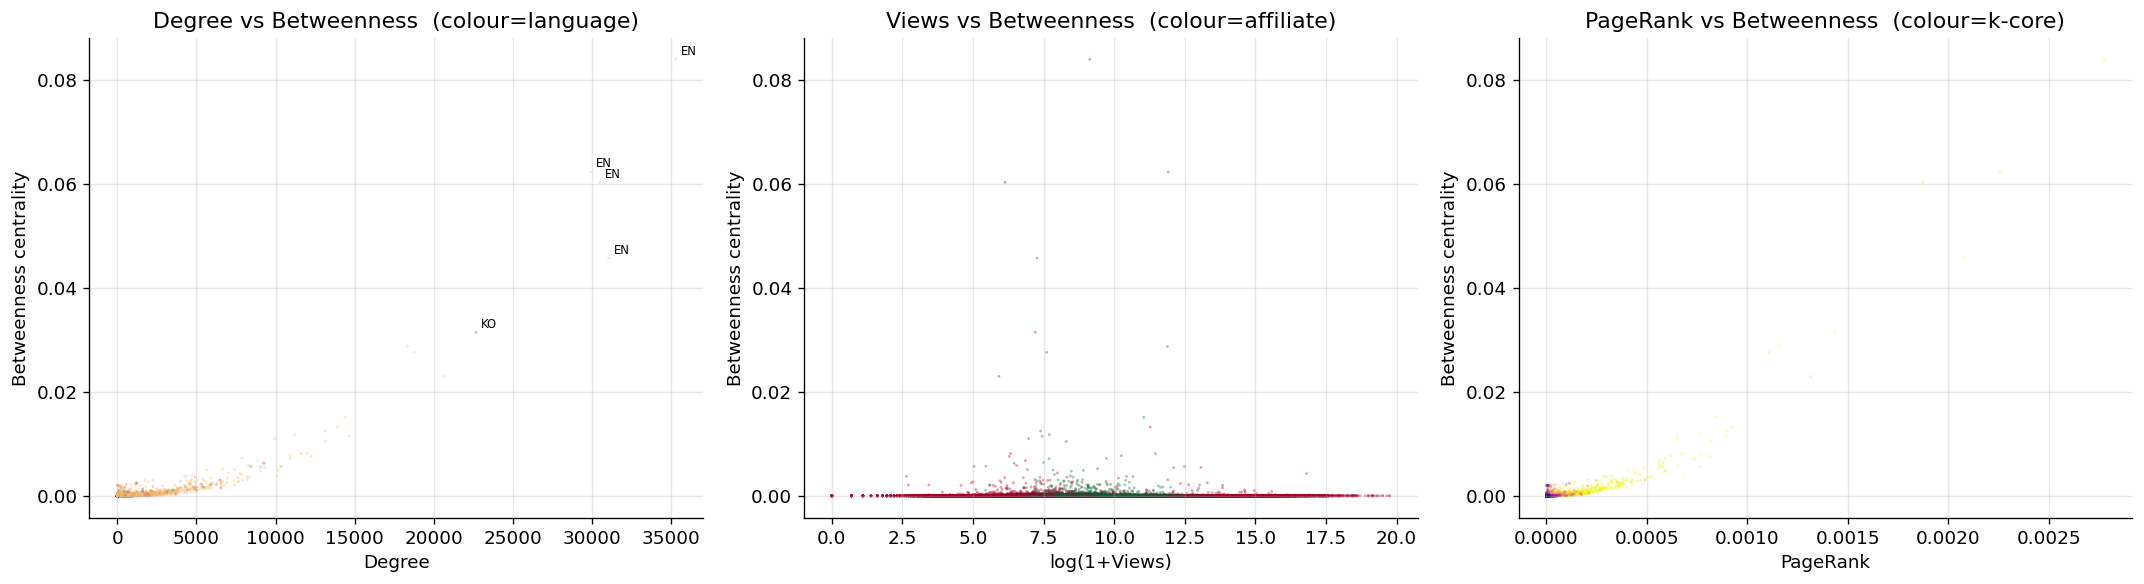

r(deg, btw)=0.757  r(views, btw)=0.000  r(pr, btw)=0.809


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmap_lang = plt.cm.tab20

axes[0].scatter(df_cent['degree'], df_cent['btw_cent'],
    c=df_cent['lang_cid'].clip(lower=0), cmap=cmap_lang, s=3, alpha=0.35, linewidths=0)
for _,r in df_cent.nlargest(5,'btw_cent').iterrows():
    axes[0].annotate(r['language'][:3], xy=(r['degree'],r['btw_cent']),
                     fontsize=7, xytext=(3,3), textcoords='offset points')
axes[0].set_xlabel('Degree'); axes[0].set_ylabel('Betweenness centrality')
axes[0].set_title('Degree vs Betweenness  (colour=language)')

axes[1].scatter(np.log1p(df_cent['views']), df_cent['btw_cent'],
    c=df_cent['affiliate'].astype(float), cmap='RdYlGn', s=3, alpha=0.35, linewidths=0)
axes[1].set_xlabel('log(1+Views)'); axes[1].set_ylabel('Betweenness centrality')
axes[1].set_title('Views vs Betweenness  (colour=affiliate)')

axes[2].scatter(df_cent['pagerank'], df_cent['btw_cent'],
    c=df_cent['kcore'], cmap='plasma', s=3, alpha=0.35, linewidths=0)
axes[2].set_xlabel('PageRank'); axes[2].set_ylabel('Betweenness centrality')
axes[2].set_title('PageRank vs Betweenness  (colour=k-core)')

plt.tight_layout(); plt.savefig('fig_centrality_scatter.png', bbox_inches='tight'); plt.show()
print(f'r(deg, btw)={corr_deg_btw:.3f}  r(views, btw)={corr_views_btw:.3f}'
      f'  r(pr, btw)={corr_pr_btw:.3f}')

## 10. Centrality Correlation & Account-Lifetime Analysis

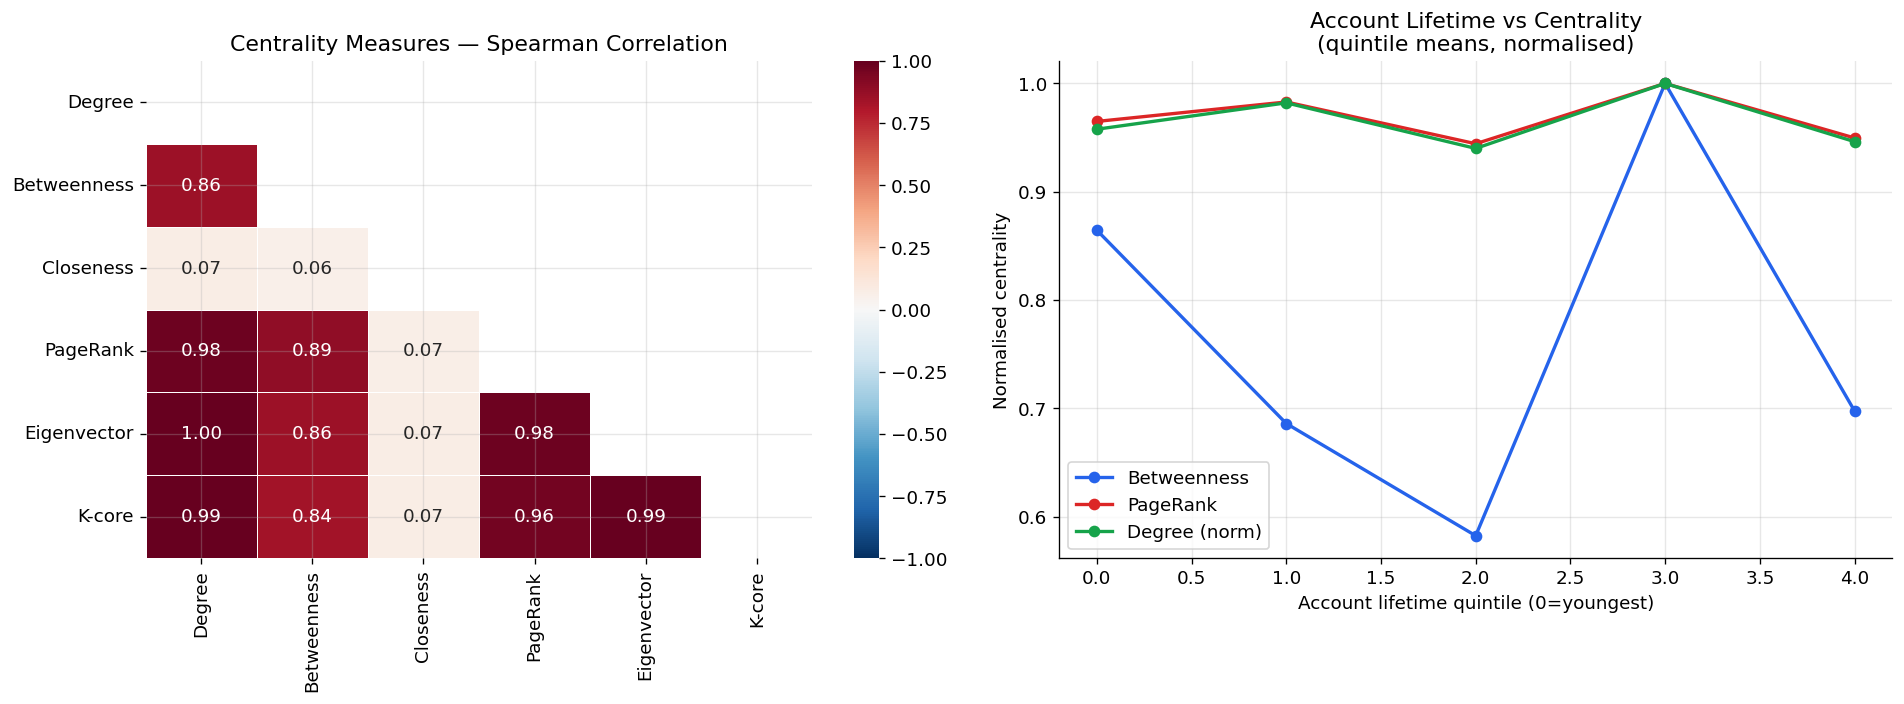

In [14]:
# ── Spearman correlation heatmap ───────────────────────────────────────────
cent_cols  = ['degree','btw_cent','clo_cent','pagerank','eig_cent','kcore']
cent_labels= ['Degree','Betweenness','Closeness','PageRank','Eigenvector','K-core']
corr_mat   = df_cent[cent_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=axes[0],
            xticklabels=cent_labels, yticklabels=cent_labels,
            linewidths=0.5)
axes[0].set_title('Centrality Measures — Spearman Correlation')

# ── Account lifetime vs centrality ────────────────────────────────────────
if df_cent['life_time'].max() > 0:
    lt_log = np.log1p(df_cent['life_time'])
    for col, label, color in [
        ('btw_cent', 'Betweenness', PALETTE[0]),
        ('pagerank',  'PageRank',   PALETTE[1]),
        ('degree',    'Degree (norm)', PALETTE[2]),
    ]:
        # Bin by lifetime quintile
        bins  = pd.qcut(lt_log, 5, labels=False, duplicates='drop')
        means = df_cent.groupby(bins)[col].mean()
        axes[1].plot(means.index, means.values / means.max(), marker='o',
                     label=label, color=color, linewidth=2)
    axes[1].set_xlabel('Account lifetime quintile (0=youngest)')
    axes[1].set_ylabel('Normalised centrality')
    axes[1].set_title('Account Lifetime vs Centrality\n(quintile means, normalised)')
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, 'life_time not available', ha='center', transform=axes[1].transAxes)

plt.tight_layout(); plt.savefig('fig_corr_lifetime.png', bbox_inches='tight'); plt.show()

## 11. Bridge Node Identification

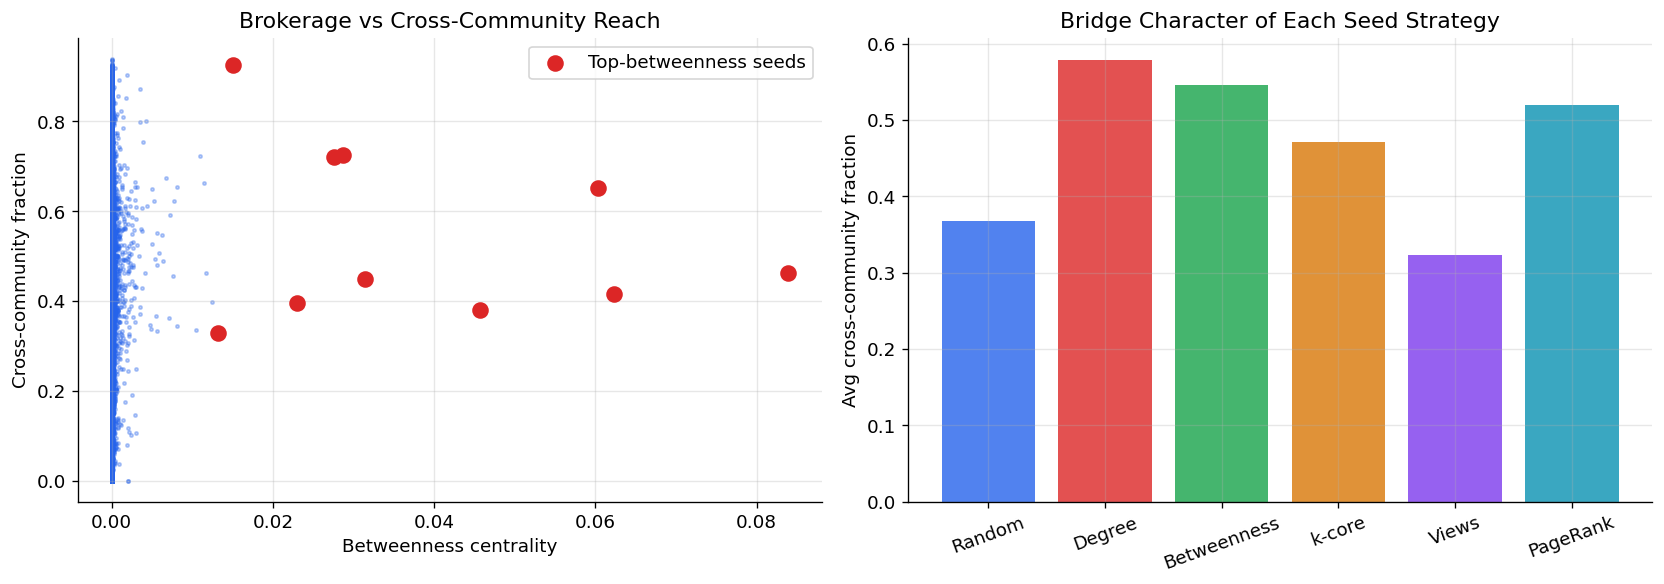

In [15]:
def cross_community_fraction(node, G, node_community):
    nb = list(G.neighbors(node))
    if not nb: return 0.0
    return sum(1 for n in nb if node_community[n] != node_community[node]) / len(nb)

df_cent['cross_comm_frac'] = df_cent['node'].apply(
    lambda n: cross_community_fraction(n, G, node_community))

TOP_K = 10
seed_random  = random.sample(list(G.nodes()), TOP_K)
seed_degree  = df_cent.nlargest(TOP_K,'degree')['node'].tolist()
seed_btw     = df_cent.nlargest(TOP_K,'btw_cent')['node'].tolist()
seed_kcore   = df_cent.nlargest(TOP_K,'kcore')['node'].tolist()
seed_views   = df_cent.nlargest(TOP_K,'views')['node'].tolist()
seed_pr      = df_cent.nlargest(TOP_K,'pagerank')['node'].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(df_cent['btw_cent'], df_cent['cross_comm_frac'],
                s=4, alpha=0.3, color=PALETTE[0])
axes[0].scatter(df_cent.loc[df_cent['node'].isin(seed_btw),'btw_cent'],
                df_cent.loc[df_cent['node'].isin(seed_btw),'cross_comm_frac'],
                s=80, color=PALETTE[1], zorder=5, label='Top-betweenness seeds')
axes[0].set_xlabel('Betweenness centrality')
axes[0].set_ylabel('Cross-community fraction')
axes[0].set_title('Brokerage vs Cross-Community Reach'); axes[0].legend()

# Cross-community fraction by strategy
labels_s = ['Random','Degree','Betweenness','k-core','Views','PageRank']
seed_sets = [seed_random,seed_degree,seed_btw,seed_kcore,seed_views,seed_pr]
cc_means  = [df_cent.loc[df_cent['node'].isin(s),'cross_comm_frac'].mean() for s in seed_sets]
axes[1].bar(labels_s, cc_means, color=PALETTE[:len(labels_s)], alpha=0.8)
axes[1].set_ylabel('Avg cross-community fraction')
axes[1].set_title('Bridge Character of Each Seed Strategy')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('fig_bridge.png', bbox_inches='tight'); plt.show()

## 12. Affiliate Network Analysis

Twitch affiliates have unlocked monetisation — they may occupy structurally
different positions than non-affiliate streamers.

Affiliates: 81,546 (48.5%)   Non-affiliates: 86,568


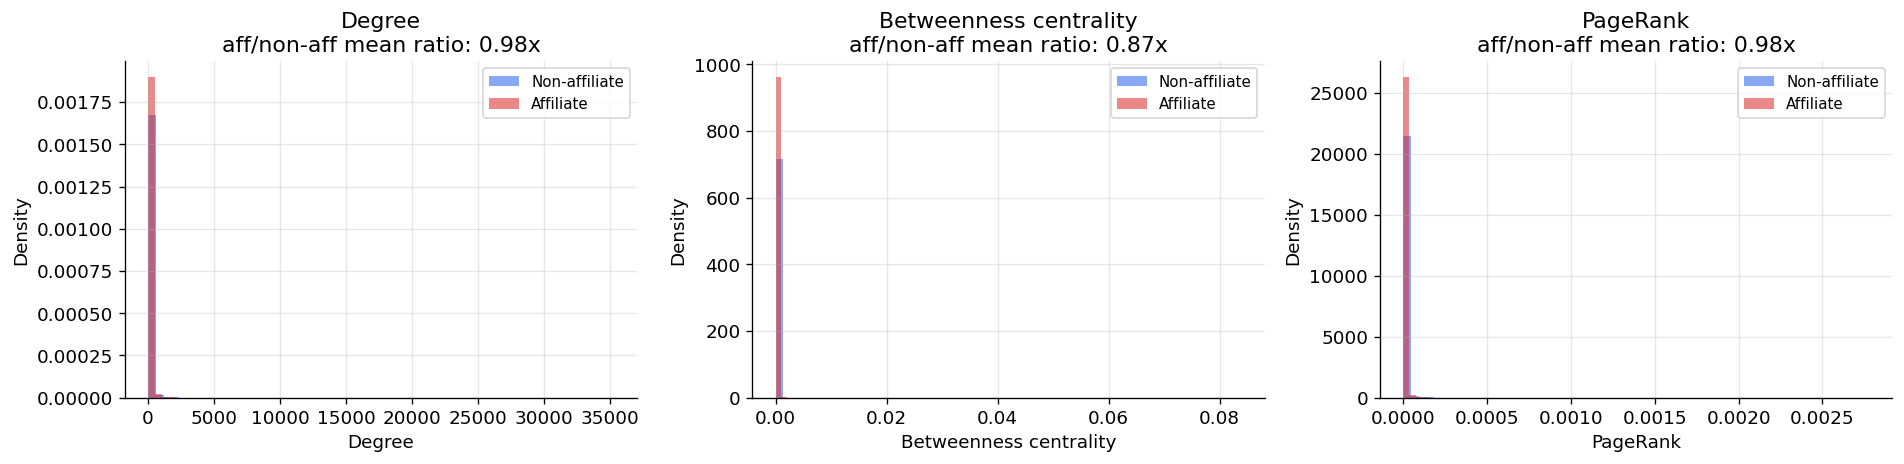


Avg cross-community fraction — affiliates: 0.352  non-affiliates: 0.353


In [16]:
aff_mask    = df_cent['affiliate'] == 1
nonaff_mask = df_cent['affiliate'] == 0
n_aff    = aff_mask.sum()
n_nonaff = nonaff_mask.sum()
print(f'Affiliates: {n_aff:,} ({n_aff/N*100:.1f}%)   Non-affiliates: {n_nonaff:,}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label in zip(axes,
    ['degree','btw_cent','pagerank'],
    ['Degree','Betweenness centrality','PageRank']):
    data_a  = df_cent.loc[aff_mask,    col]
    data_na = df_cent.loc[nonaff_mask, col]
    ax.hist(data_na, bins=60, alpha=0.55, color=PALETTE[0], density=True, label='Non-affiliate')
    ax.hist(data_a,  bins=60, alpha=0.55, color=PALETTE[1], density=True, label='Affiliate')
    ax.set_xlabel(label); ax.set_ylabel('Density')
    ax.legend(fontsize=9)
    ratio = data_a.mean() / data_na.mean() if data_na.mean() > 0 else float('nan')
    ax.set_title(f'{label}\naff/non-aff mean ratio: {ratio:.2f}x')
plt.tight_layout(); plt.savefig('fig_affiliate_centrality.png', bbox_inches='tight'); plt.show()

# Cross-community fractions
cc_aff    = df_cent.loc[aff_mask,    'cross_comm_frac'].mean()
cc_nonaff = df_cent.loc[nonaff_mask, 'cross_comm_frac'].mean()
print(f'\nAvg cross-community fraction — affiliates: {cc_aff:.3f}  non-affiliates: {cc_nonaff:.3f}')
seed_aff_btw    = df_cent[aff_mask].nlargest(TOP_K,'btw_cent')['node'].tolist()
seed_nonaff_btw = df_cent[nonaff_mask].nlargest(TOP_K,'btw_cent')['node'].tolist()

## 13. Network Resilience & Percolation Threshold

We remove up to 10,000 nodes (≈6 % of the network) under six strategies and track
the largest connected component.

The **percolation threshold** f_c (random removal) can be estimated analytically
from the Molloy-Reed criterion: f_c ≈ 1 − 1/(κ−1)  where κ=⟨k²⟩/⟨k⟩.

In [17]:
%%time
# ── Analytical percolation threshold ──────────────────────────────────────
k1 = degrees_arr.mean()
k2 = (degrees_arr**2).mean()
kappa = k2 / k1
fc_analytical = 1.0 - 1.0 / (kappa - 1.0)
print(f'⟨k⟩={k1:.2f}  ⟨k²⟩={k2:.2f}  κ={kappa:.2f}')
print(f'Analytical random-removal threshold: f_c ≈ {fc_analytical:.4f} '
      f'({fc_analytical*N:.0f} nodes)')

def resilience_experiment(G, order, steps):
    H = G.copy(); orig = G.number_of_nodes(); fracs=[1.0]; removed=0
    for node in order:
        if removed >= steps: break
        if node not in H:    continue
        H.remove_node(node); removed += 1
        fracs.append(max(len(c) for c in nx.connected_components(H)) / orig)
    return np.array(fracs)

REMOVAL_STEPS = 10_000   # ≈ 6% of 168K

order_random = random.sample(list(G.nodes()), N)
order_degree = [n for n,_ in sorted(G.degree(), key=lambda x:-x[1])]
order_btw    = [n for n,_ in sorted(btw_cent.items(), key=lambda x:-x[1])]
order_kcore  = [n for n,_ in sorted(kcore_num.items(), key=lambda x:-x[1])]
order_pr     = [n for n,_ in sorted(pr_cent.items(), key=lambda x:-x[1])]
order_views  = df_cent.sort_values('views',ascending=False)['node'].tolist()

print('Running resilience experiments (6 strategies × 10 K steps)…')
res = {}
for label, order in [
    ('Random',      order_random),
    ('High-degree', order_degree),
    ('High-betw.',  order_btw),
    ('High-kcore',  order_kcore),
    ('High-PR',     order_pr),
    ('High-views',  order_views),
]:
    res[label] = resilience_experiment(G, order, REMOVAL_STEPS)
    print(f'  ✓ {label}')

⟨k⟩=80.87  ⟨k²⟩=105237.34  κ=1301.34
Analytical random-removal threshold: f_c ≈ 0.9992 (167985 nodes)
Running resilience experiments (6 strategies × 10 K steps)…
  ✓ Random
  ✓ High-degree
  ✓ High-betw.
  ✓ High-kcore
  ✓ High-PR
  ✓ High-views
CPU times: user 4h 11min 26s, sys: 2min 57s, total: 4h 14min 23s
Wall time: 4h 14min 19s


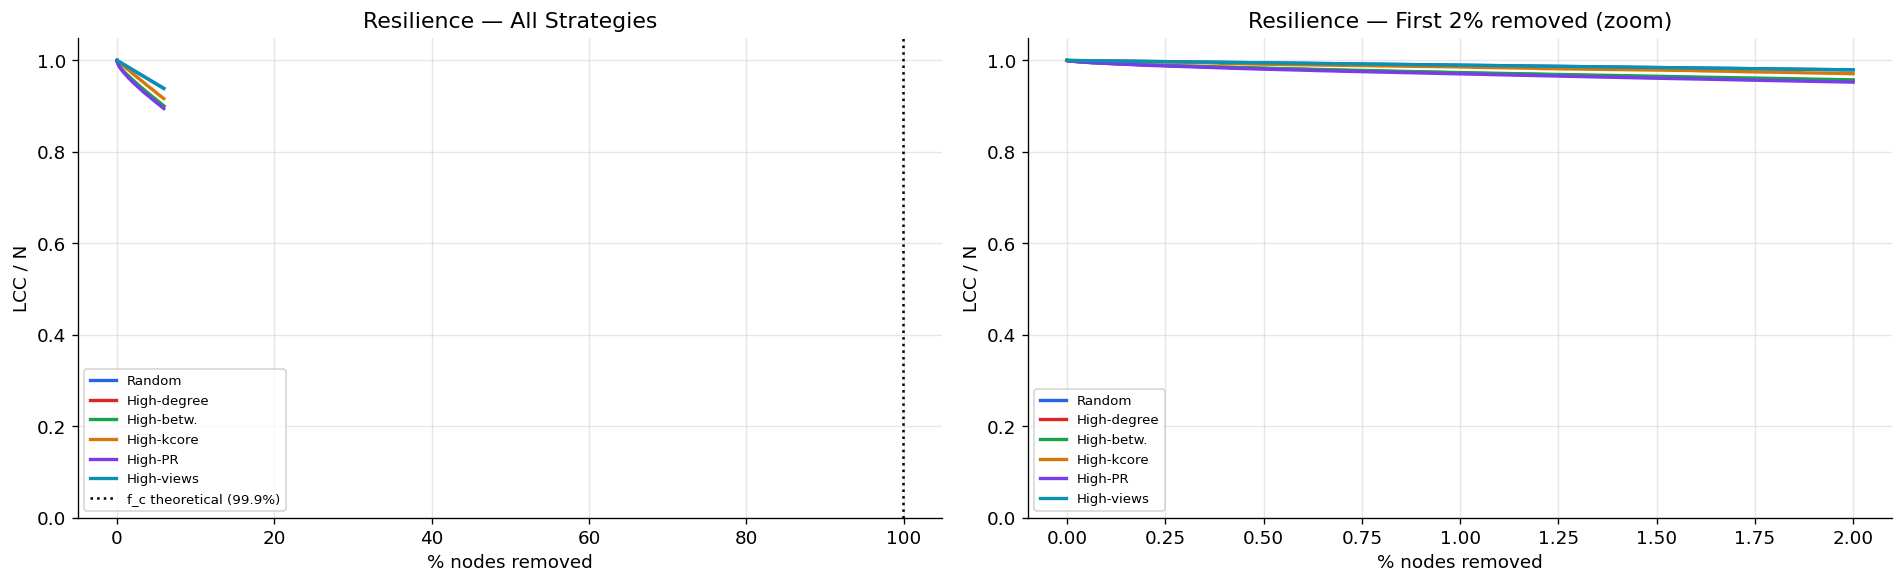

LCC after 1% removal:
  Random        : 0.9897
  High-degree   : 0.9728
  High-betw.    : 0.9735
  High-kcore    : 0.9858
  High-PR       : 0.9704
  High-views    : 0.9897


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors6 = PALETTE[:6]

for (label, fracs), color in zip(res.items(), colors6):
    x = np.arange(len(fracs)) / N * 100
    axes[0].plot(x, fracs, label=label, color=color, linewidth=2)
axes[0].axvline(fc_analytical*100, color='black', ls=':', lw=1.5,
                label=f'f_c theoretical ({fc_analytical*100:.1f}%)')
axes[0].set_xlabel('% nodes removed'); axes[0].set_ylabel('LCC / N')
axes[0].set_title('Resilience — All Strategies'); axes[0].legend(fontsize=8)
axes[0].set_ylim(0,1.05)

# Zoom: first 2%
idx2 = int(0.02*N)
for (label, fracs), color in zip(res.items(), colors6):
    x = np.arange(min(len(fracs), idx2+1)) / N * 100
    axes[1].plot(x, fracs[:idx2+1], label=label, color=color, linewidth=2)
axes[1].set_xlabel('% nodes removed'); axes[1].set_ylabel('LCC / N')
axes[1].set_title('Resilience — First 2% removed (zoom)'); axes[1].legend(fontsize=8)
axes[1].set_ylim(0,1.05)
plt.tight_layout(); plt.savefig('fig_resilience.png', bbox_inches='tight'); plt.show()

idx1pct = int(0.01*N)
print('LCC after 1% removal:')
for label, fracs in res.items():
    print(f'  {label:<14}: {fracs[min(idx1pct,len(fracs)-1)]:.4f}')

## 14. SIR Diffusion Simulation *(GPU — 200 runs, 150 steps)*

All 200 Monte-Carlo replications run in one GPU kernel per timestep via CuPy sparse SpMM.
State tensors: `(200, 168 114)` int8 = 33 MB — trivial on 102 GB VRAM.

In [19]:
# ── Build GPU sparse adjacency matrix ─────────────────────────────────────
nodes_ordered = sorted(G.nodes())
n2i_sir       = {n: i for i, n in enumerate(nodes_ordered)}

# Build index arrays as numpy first (avoids 13.6M-element Python list overhead)
src_arr = np.array([n2i_sir[u] for u, v in G.edges()], dtype=np.int32)
dst_arr = np.array([n2i_sir[v] for u, v in G.edges()], dtype=np.int32)
# Undirected → both directions
rows_np = np.concatenate([src_arr, dst_arr])
cols_np = np.concatenate([dst_arr, src_arr])
data_np = np.ones(len(rows_np), dtype=np.float32)

# SciPy CSR (always built; used if CuPy is unavailable)
A_sp = sp.csr_matrix((data_np, (rows_np, cols_np)), shape=(N, N))

if CUPY_OK:
    # ── WHY pinned memory must be disabled ────────────────────────────────
    # CuPy's default async transfer path calls cudaHostAlloc() to allocate
    # pinned (page-locked) host memory.  If any previous CUDA call in this
    # session raised an error (e.g. the cuGraph betweenness OOM), the CUDA
    # runtime may retain a dirty error flag that causes every subsequent
    # cudaHostAlloc to return cudaErrorIllegalAddress — even though VRAM
    # is plentiful.  Setting the allocator to None forces CuPy to use
    # ordinary pageable memory (cudaMemcpy), which bypasses the flag check.
    cp.cuda.set_pinned_memory_allocator(None)

    # Also flush both memory pools to release any fragmented blocks
    cp.get_default_memory_pool().free_all_blocks()
    cp.get_default_pinned_memory_pool().free_all_blocks()

    # Transfer numpy arrays to GPU and build COO → CSR
    rows_gpu = cp.asarray(rows_np)
    cols_gpu = cp.asarray(cols_np)
    data_gpu = cp.asarray(data_np)

    A_mat = cpsp.coo_matrix(
        (data_gpu, (rows_gpu, cols_gpu)), shape=(N, N)
    ).tocsr()

    nnz_gb = A_mat.nnz * 8 / 1024**3   # int32 indices + float32 data ≈ 8 B/entry
    print(f'GPU CSR: {A_mat.shape}  nnz={A_mat.nnz:,}  mem≈{nnz_gb:.2f} GB')

    free_b, total_b = cp.cuda.runtime.memGetInfo()
    print(f'VRAM after upload: {free_b/1024**3:.1f} free / {total_b/1024**3:.0f} GB total')
else:
    A_mat = A_sp
    print('CPU fallback (SciPy sparse)')


GPU CSR: (168114, 168114)  nnz=13,595,114  mem≈0.10 GB
VRAM after upload: 93.3 free / 95 GB total


In [20]:
def sir_gpu(A_mat, seed_idx, beta=0.05, gamma=0.05,
            max_steps=150, n_runs=200,
            track_comms=False, comm_arr_gpu=None, n_comms=0):
    """
    Vectorised SIR.  All n_runs replications run in parallel.
    Uses (A @ I.T).T  to avoid the unsupported dense@sparse direction in CuPy.
    Returns: I_curves (n_runs, T+1), final_R (n_runs,), comms_hit list or None.
    """
    use_gpu = CUPY_OK and hasattr(A_mat, 'get')
    xp = cp if use_gpu else np

    state         = xp.zeros((n_runs, N), dtype=xp.int8)
    state[:, seed_idx] = 1
    I_curves      = xp.zeros((n_runs, max_steps+1), dtype=xp.int32)
    I_curves[:,0] = len(seed_idx)

    comm_reached = None
    if track_comms and comm_arr_gpu is not None and n_comms > 0:
        comm_reached = xp.zeros((n_runs, n_comms), dtype=xp.bool_)
        comm_reached[:, xp.unique(comm_arr_gpu[seed_idx])] = True

    for t in range(max_steps):
        I_f = (state==1).astype(xp.float32)
        if I_f.sum() == 0:
            I_curves[:,t+1:] = 0; break
        S_f = (state==0)
        n_inf = (A_mat @ I_f.T).T          # (N,N)@(N,runs)→(N,runs) then .T
        p_inf = 1.0 - (1.0 - beta)**n_inf
        new_I = (xp.random.random((n_runs,N)).astype(xp.float32) < p_inf) & S_f
        new_R = (xp.random.random((n_runs,N)).astype(xp.float32) < gamma) & (state==1)
        state[new_I] = 1; state[new_R] = 2
        if comm_reached is not None:
            w = xp.where(new_I)
            if w[0].size > 0:
                comm_reached[w[0], comm_arr_gpu[w[1]]] = True
        I_curves[:,t+1] = (state==1).sum(axis=1)

    final_R   = (state==2).sum(axis=1)
    comms_hit = comm_reached.sum(axis=1).tolist() if comm_reached is not None else None
    if use_gpu:
        return cp.asnumpy(I_curves), cp.asnumpy(final_R), comms_hit
    return I_curves, final_R, comms_hit

# ── Community label array on GPU ────────────────────────────────────────────
comm_arr_gpu = (cp if CUPY_OK else np).array(
    [node_community.get(nodes_ordered[i],-1) for i in range(N)], dtype=(cp if CUPY_OK else np).int32
)
n_comm_gpu = int(comm_arr_gpu.max())+1

In [21]:
%%time
N_RUNS = 200; BETA = 0.05; GAMMA = 0.05; T_MAX = 150

seed_strategies = {
    'Random':      seed_random,
    'High-degree': seed_degree,
    'High-betw.':  seed_btw,
    'High-kcore':  seed_kcore,
    'High-views':  seed_views,
    'High-PR':     seed_pr,
}
sim_results = {}

print(f'{N_RUNS} runs × {T_MAX} steps, β={BETA} γ={GAMMA}\n')
for strat, seeds in seed_strategies.items():
    idx = [n2i_sir[n] for n in seeds if n in n2i_sir]
    I_c, fR, comms = sir_gpu(A_mat, idx, beta=BETA, gamma=GAMMA,
                              max_steps=T_MAX, n_runs=N_RUNS,
                              track_comms=True, comm_arr_gpu=comm_arr_gpu,
                              n_comms=n_comm_gpu)
    sim_results[strat] = {'I':I_c,'final_R':fR,'comms':comms}
    mR = np.mean(fR); mc = np.mean(comms) if comms else float('nan')
    print(f'  {strat:<14}: R={mR:>8,.0f} ({mR/N*100:.1f}%)  comms={mc:.1f}')

200 runs × 150 steps, β=0.05 γ=0.05

  Random        : R= 164,194 (97.7%)  comms=34.1
  High-degree   : R= 164,215 (97.7%)  comms=34.2
  High-betw.    : R= 164,203 (97.7%)  comms=34.1
  High-kcore    : R= 164,205 (97.7%)  comms=34.2
  High-views    : R= 164,213 (97.7%)  comms=34.2
  High-PR       : R= 164,217 (97.7%)  comms=34.2
CPU times: user 23.6 s, sys: 71 ms, total: 23.7 s
Wall time: 23.8 s


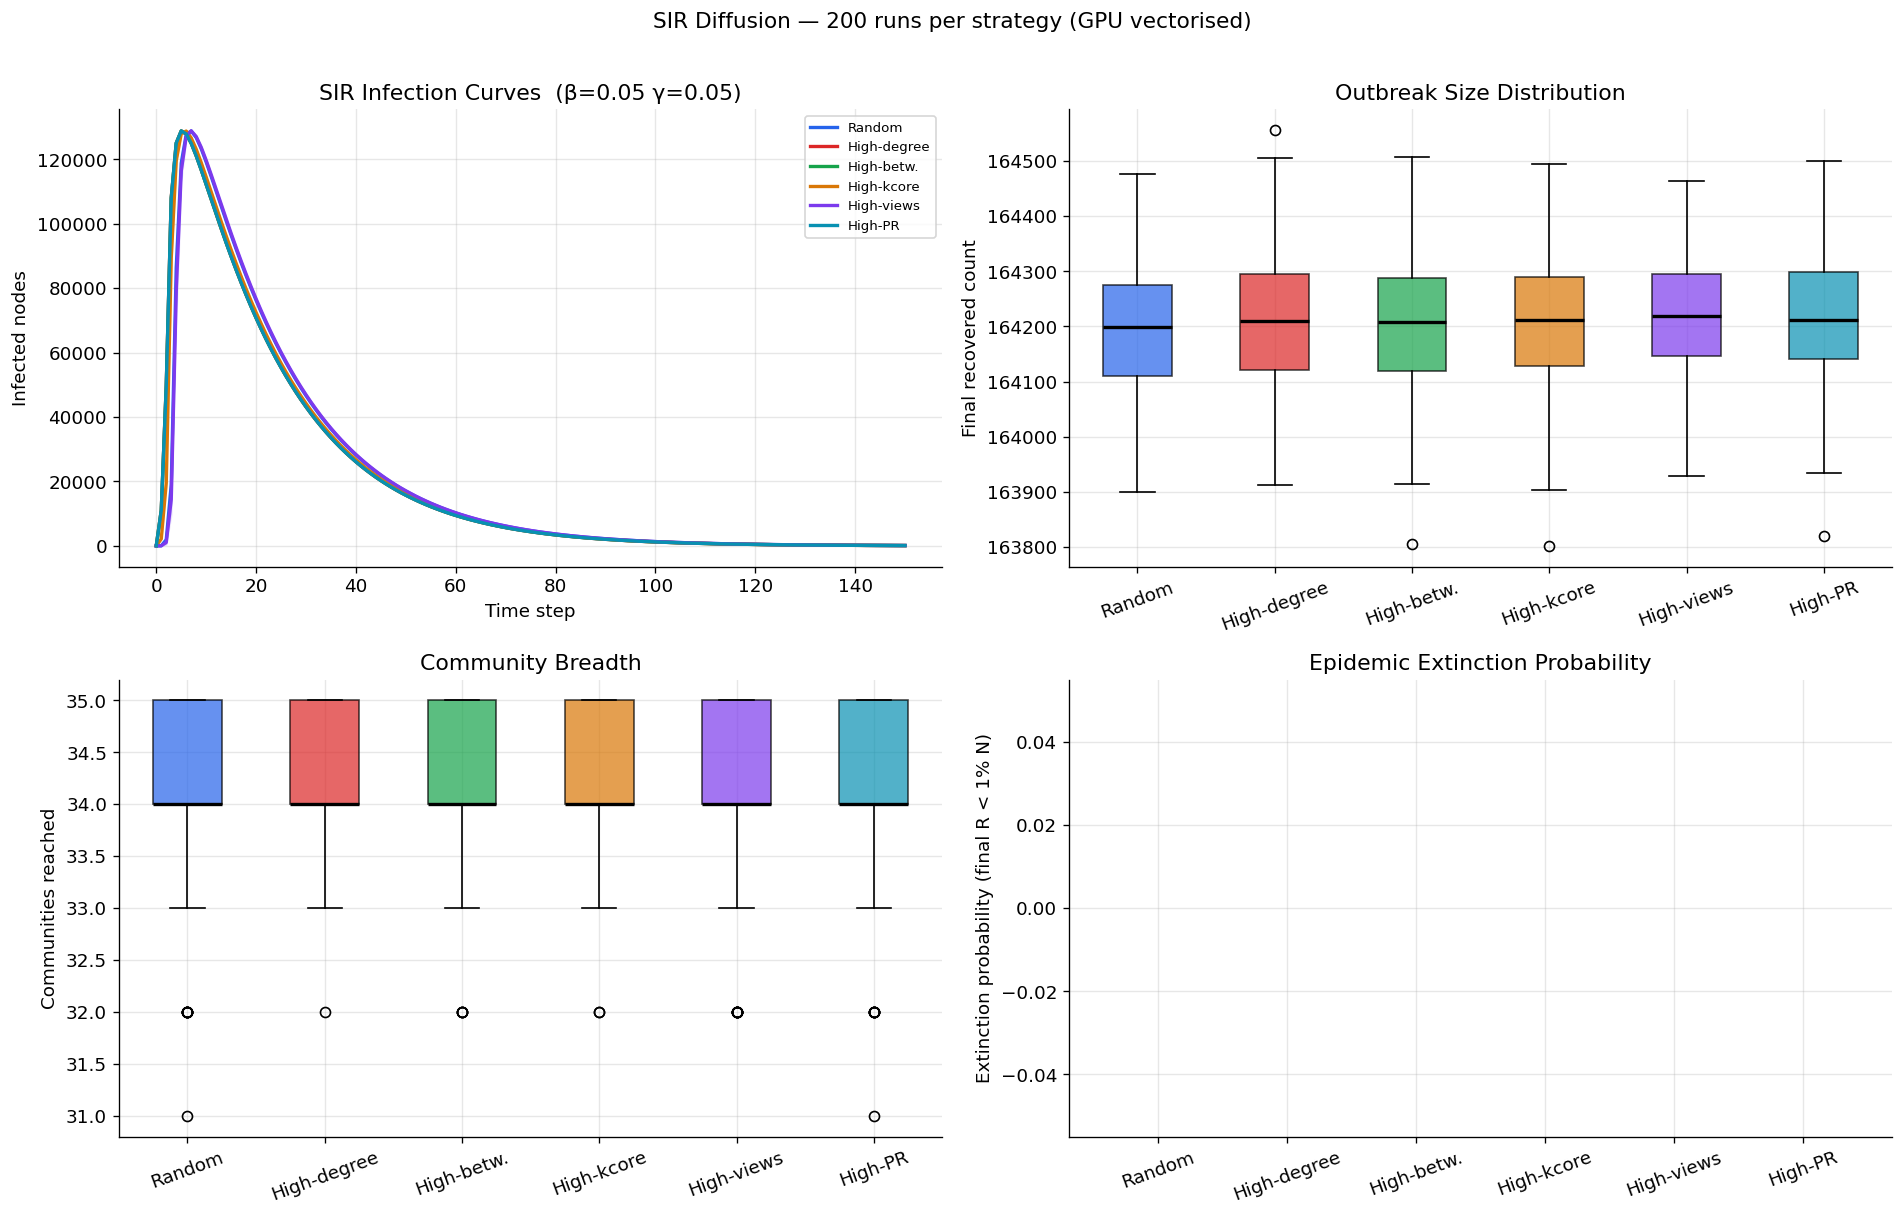

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
colors6 = PALETTE[:6]

# Infection curves
for (strat,data),c in zip(sim_results.items(), colors6):
    I = data['I']; mu=I.mean(0); sd=I.std(0); t=np.arange(I.shape[1])
    axes[0,0].plot(t, mu, label=strat, color=c, lw=2)
    axes[0,0].fill_between(t, mu-sd, mu+sd, alpha=0.12, color=c)
axes[0,0].set_xlabel('Time step'); axes[0,0].set_ylabel('Infected nodes')
axes[0,0].set_title(f'SIR Infection Curves  (β={BETA} γ={GAMMA})'); axes[0,0].legend(fontsize=8)

# Final R boxplot
bp = axes[0,1].boxplot([sim_results[s]['final_R'].tolist() for s in seed_strategies],
    labels=list(seed_strategies.keys()), patch_artist=True,
    medianprops={'color':'black','linewidth':2})
for patch,c in zip(bp['boxes'], colors6): patch.set_facecolor(c); patch.set_alpha(0.7)
axes[0,1].set_ylabel('Final recovered count')
axes[0,1].set_title('Outbreak Size Distribution')
axes[0,1].tick_params(axis='x', rotation=20)

# Communities hit boxplot
comms_data = [sim_results[s]['comms'] or [0]*N_RUNS for s in seed_strategies]
bp2 = axes[1,0].boxplot(comms_data, labels=list(seed_strategies.keys()),
    patch_artist=True, medianprops={'color':'black','linewidth':2})
for patch,c in zip(bp2['boxes'], colors6): patch.set_facecolor(c); patch.set_alpha(0.7)
axes[1,0].set_ylabel('Communities reached'); axes[1,0].set_title('Community Breadth')
axes[1,0].tick_params(axis='x', rotation=20)

# Extinction probability (< 1% final R)
thresh = int(0.01*N)
ext_prob = {s: (sim_results[s]['final_R'] < thresh).mean() for s in seed_strategies}
axes[1,1].bar(list(ext_prob.keys()), list(ext_prob.values()), color=colors6, alpha=0.8)
axes[1,1].set_ylabel('Extinction probability (final R < 1% N)')
axes[1,1].set_title('Epidemic Extinction Probability')
axes[1,1].tick_params(axis='x', rotation=20)

plt.suptitle('SIR Diffusion — 200 runs per strategy (GPU vectorised)', fontsize=13, y=1.01)
plt.tight_layout(); plt.savefig('fig_sir_main.png', bbox_inches='tight'); plt.show()

## 15. SIR Parameter Sweep *(120 combos × 100 runs on GPU)*

We sweep β ∈ [0.005, 0.25] × γ ∈ [0.01 … 0.50] and run 100 GPU-vectorised SIR
replications per combination.  With 102 GB VRAM and Blackwell SpMM throughput
the full 120-combination sweep completes in a few minutes.

In [23]:
%%time
beta_vals  = np.linspace(0.005, 0.25, 15)
gamma_vals = np.array([0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50])
N_RUNS_SW  = 100
T_MAX_SW   = 150
sweep_idx  = [n2i_sir[n] for n in seed_btw if n in n2i_sir]

sweep_mean = np.zeros((len(beta_vals), len(gamma_vals)))
sweep_std  = np.zeros((len(beta_vals), len(gamma_vals)))
sweep_var  = np.zeros((len(beta_vals), len(gamma_vals)))

total = len(beta_vals)*len(gamma_vals)
done  = 0
for bi, beta in enumerate(beta_vals):
    for gi, gamma in enumerate(gamma_vals):
        _, fR, _ = sir_gpu(A_mat, sweep_idx, beta=beta, gamma=gamma,
                            max_steps=T_MAX_SW, n_runs=N_RUNS_SW)
        ar = fR / N
        sweep_mean[bi,gi] = ar.mean()
        sweep_std[bi,gi]  = ar.std()
        sweep_var[bi,gi]  = ar.var()
        done += 1
        if done % 20 == 0:
            print(f'  {done}/{total} combinations done…')

print(f'Sweep complete — {total} combinations.')

  20/120 combinations done…
  40/120 combinations done…
  60/120 combinations done…
  80/120 combinations done…
  100/120 combinations done…
  120/120 combinations done…
Sweep complete — 120 combinations.
CPU times: user 2min 59s, sys: 80.9 ms, total: 2min 59s
Wall time: 2min 59s


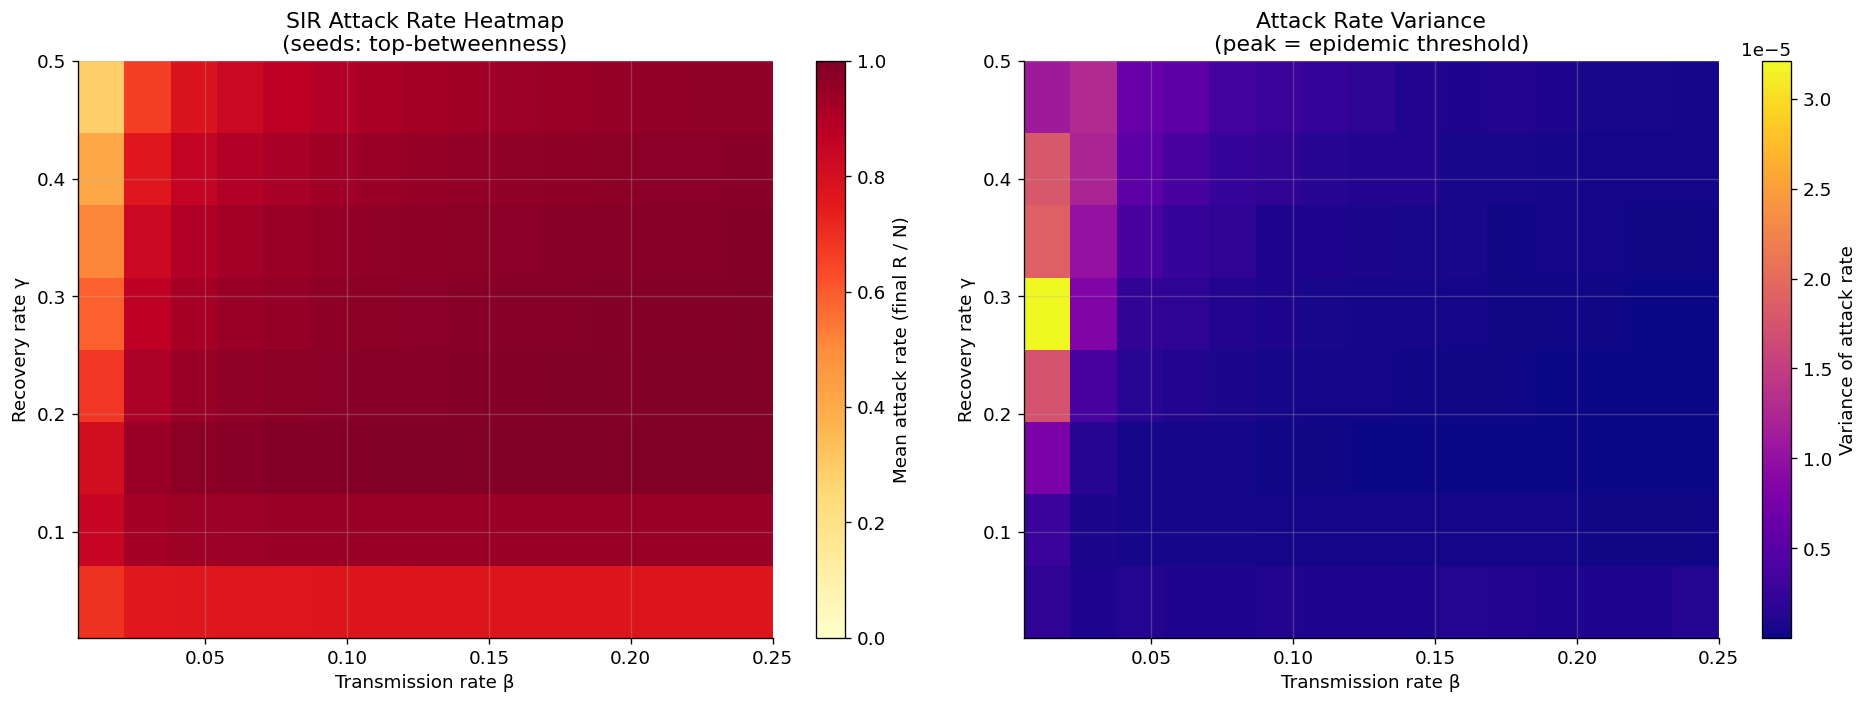

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Attack-rate heatmap
im = axes[0].imshow(sweep_mean.T, aspect='auto', origin='lower',
                    cmap='YlOrRd', vmin=0, vmax=1,
                    extent=[beta_vals[0], beta_vals[-1],
                            gamma_vals[0], gamma_vals[-1]])
plt.colorbar(im, ax=axes[0], label='Mean attack rate (final R / N)')
axes[0].set_xlabel('Transmission rate β'); axes[0].set_ylabel('Recovery rate γ')
axes[0].set_title('SIR Attack Rate Heatmap\n(seeds: top-betweenness)')

# Variance heatmap (peaks near epidemic threshold)
im2 = axes[1].imshow(sweep_var.T, aspect='auto', origin='lower',
                     cmap='plasma',
                     extent=[beta_vals[0], beta_vals[-1],
                             gamma_vals[0], gamma_vals[-1]])
plt.colorbar(im2, ax=axes[1], label='Variance of attack rate')
axes[1].set_xlabel('Transmission rate β'); axes[1].set_ylabel('Recovery rate γ')
axes[1].set_title('Attack Rate Variance\n(peak = epidemic threshold)')

plt.tight_layout(); plt.savefig('fig_sweep_heatmap.png', bbox_inches='tight'); plt.show()

## 16. Epidemic Threshold — Analytical & Empirical

**Heterogeneous mean-field (HMF) threshold** for SIR on a network:

    R₀ = β/γ × (⟨k²⟩ − ⟨k⟩) / ⟨k⟩ = 1  ⟹  β_c = γ⟨k⟩/(⟨k²⟩−⟨k⟩)

Near the threshold, stochastic fluctuations are maximised — **variance of epidemic size peaks**,
a signature of critical slowing down.  We locate β_c empirically as the argmax of variance.

Analytical epidemic thresholds β_c(γ):
  γ=0.01  β_c=0.0000  (R₀ range in sweep: 650.17–32508.51)
  γ=0.02  β_c=0.0000  (R₀ range in sweep: 325.09–16254.25)
  γ=0.05  β_c=0.0000  (R₀ range in sweep: 130.03–6501.70)
  γ=0.10  β_c=0.0001  (R₀ range in sweep: 65.02–3250.85)
  γ=0.15  β_c=0.0001  (R₀ range in sweep: 43.34–2167.23)
  γ=0.20  β_c=0.0002  (R₀ range in sweep: 32.51–1625.43)
  γ=0.30  β_c=0.0002  (R₀ range in sweep: 21.67–1083.62)
  γ=0.50  β_c=0.0004  (R₀ range in sweep: 13.00–650.17)


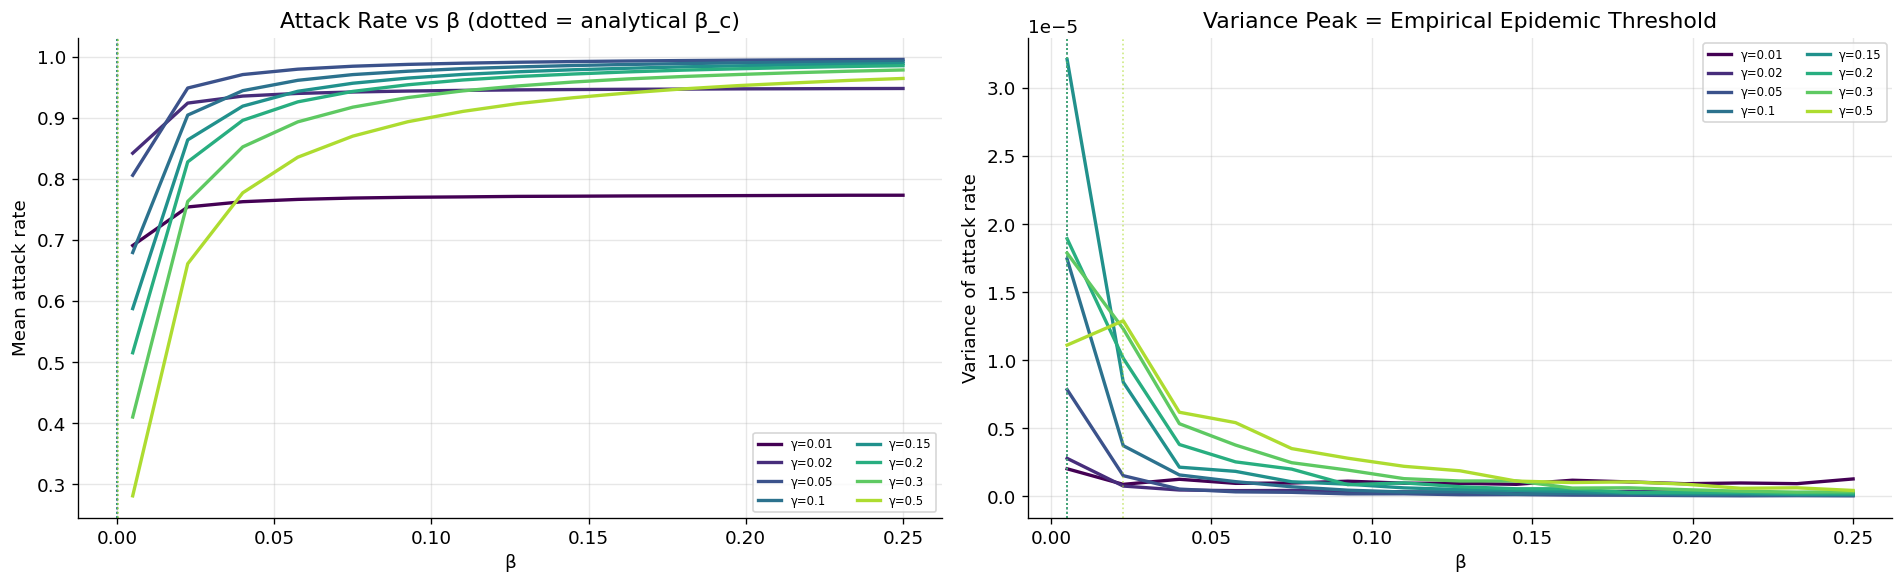


Analytical vs empirical β_c:
  γ=0.01  β_c analytic=0.0000  empirical=0.0050
  γ=0.02  β_c analytic=0.0000  empirical=0.0050
  γ=0.05  β_c analytic=0.0000  empirical=0.0050
  γ=0.10  β_c analytic=0.0001  empirical=0.0050
  γ=0.15  β_c analytic=0.0001  empirical=0.0050
  γ=0.20  β_c analytic=0.0002  empirical=0.0050
  γ=0.30  β_c analytic=0.0002  empirical=0.0050
  γ=0.50  β_c analytic=0.0004  empirical=0.0225


In [25]:
beta_c_analytic = gamma_vals * k1 / (k2 - k1)
print('Analytical epidemic thresholds β_c(γ):')
for g, bc in zip(gamma_vals, beta_c_analytic):
    R0_at_sweep_beta = beta_vals / g * (k2 - k1) / k1
    print(f'  γ={g:.2f}  β_c={bc:.4f}  '
          f'(R₀ range in sweep: {R0_at_sweep_beta[0]:.2f}–{R0_at_sweep_beta[-1]:.2f})')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Mean attack rate vs β for each γ
for gi, gamma in enumerate(gamma_vals):
    axes[0].plot(beta_vals, sweep_mean[:,gi], label=f'γ={gamma}',
                 color=plt.cm.viridis(gi/len(gamma_vals)), lw=2)
    axes[0].axvline(beta_c_analytic[gi], color=plt.cm.viridis(gi/len(gamma_vals)),
                    ls=':', lw=1, alpha=0.6)
axes[0].set_xlabel('β'); axes[0].set_ylabel('Mean attack rate')
axes[0].set_title('Attack Rate vs β (dotted = analytical β_c)')
axes[0].legend(fontsize=7, ncol=2)

# Variance vs β — peak = empirical threshold
beta_c_empirical = []
for gi, gamma in enumerate(gamma_vals):
    var_curve = sweep_var[:,gi]
    bc_emp    = beta_vals[np.argmax(var_curve)]
    beta_c_empirical.append(bc_emp)
    axes[1].plot(beta_vals, var_curve, label=f'γ={gamma}',
                 color=plt.cm.viridis(gi/len(gamma_vals)), lw=2)
    axes[1].axvline(bc_emp, color=plt.cm.viridis(gi/len(gamma_vals)),
                    ls=':', lw=1, alpha=0.6)
axes[1].set_xlabel('β'); axes[1].set_ylabel('Variance of attack rate')
axes[1].set_title('Variance Peak = Empirical Epidemic Threshold')
axes[1].legend(fontsize=7, ncol=2)

plt.tight_layout(); plt.savefig('fig_threshold.png', bbox_inches='tight'); plt.show()

print('\nAnalytical vs empirical β_c:')
for g, ba, be in zip(gamma_vals, beta_c_analytic, beta_c_empirical):
    print(f'  γ={g:.2f}  β_c analytic={ba:.4f}  empirical={be:.4f}')

## 17. Language-Seeded SIR & Language Barrier Analysis

We seed the epidemic from 10 nodes drawn from each of the top 12 language
communities and record the final outbreak size.

The originally proposed **language barrier ratio** — infected outside the
seeding language divided by total infected — was not implemented in the
executed run. The second panel instead plots `final_R / language pool size`,
which is dominated by language size: a small community can show a large
"amplification" simply because its denominator is small. The per-language
final outbreak sizes are the reliable comparison here.


In [26]:
%%time
top_lang_list = lang_counts.head(12).index.tolist()
N_RUNS_LS     = 100
BETA_LS       = 0.05
GAMMA_LS      = 0.05

lang_sir      = {}   # lang → {final_R, frac_outside}

# Language membership arrays for tracking
lang_node_sets = {l: [n for n in G.nodes()
                       if G.nodes[n].get('language') == l and n in n2i_sir]
                  for l in top_lang_list}

# Build node→language_cid array on GPU
lang_arr = (cp if CUPY_OK else np).array(
    [lang2cid.get(G.nodes[nodes_ordered[i]].get('language'),-1) for i in range(N)],
    dtype=(cp if CUPY_OK else np).int32
)

for lang in top_lang_list:
    pool = lang_node_sets.get(lang, [])
    if len(pool) < 10: continue
    seed_nodes = random.sample(pool, 10)
    seed_idx   = [n2i_sir[n] for n in seed_nodes]

    _, fR, _ = sir_gpu(A_mat, seed_idx, beta=BETA_LS, gamma=GAMMA_LS,
                        max_steps=T_MAX, n_runs=N_RUNS_LS)
    # Rough estimate: fraction of all nodes not in seeding language
    frac_outside = sum(1 for n in G.nodes()
                       if G.nodes[n].get('language') != lang) / N
    lang_sir[lang] = {
        'final_R':       float(fR.mean()),
        'final_R_std':   float(fR.std()),
        'n_lang':        len(pool),
        'frac_outside':  frac_outside,
    }
    print(f'  {lang:<12}: R={fR.mean():>7,.0f} ({fR.mean()/N*100:.1f}%)  '
          f'pool={len(pool):,}')

  EN          : R=164,189 (97.7%)  pool=124,411
  DE          : R=164,214 (97.7%)  pool=9,428
  FR          : R=164,188 (97.7%)  pool=6,799
  ES          : R=164,201 (97.7%)  pool=5,699
  RU          : R=164,227 (97.7%)  pool=4,821
  ZH          : R=164,210 (97.7%)  pool=2,828
  PT          : R=164,218 (97.7%)  pool=2,536
  OTHER       : R=164,208 (97.7%)  pool=1,429
  JA          : R=164,224 (97.7%)  pool=1,327
  IT          : R=164,205 (97.7%)  pool=1,230
  KO          : R=164,205 (97.7%)  pool=1,215
  PL          : R=164,189 (97.7%)  pool=944
CPU times: user 21.3 s, sys: 13.9 ms, total: 21.3 s
Wall time: 21.3 s


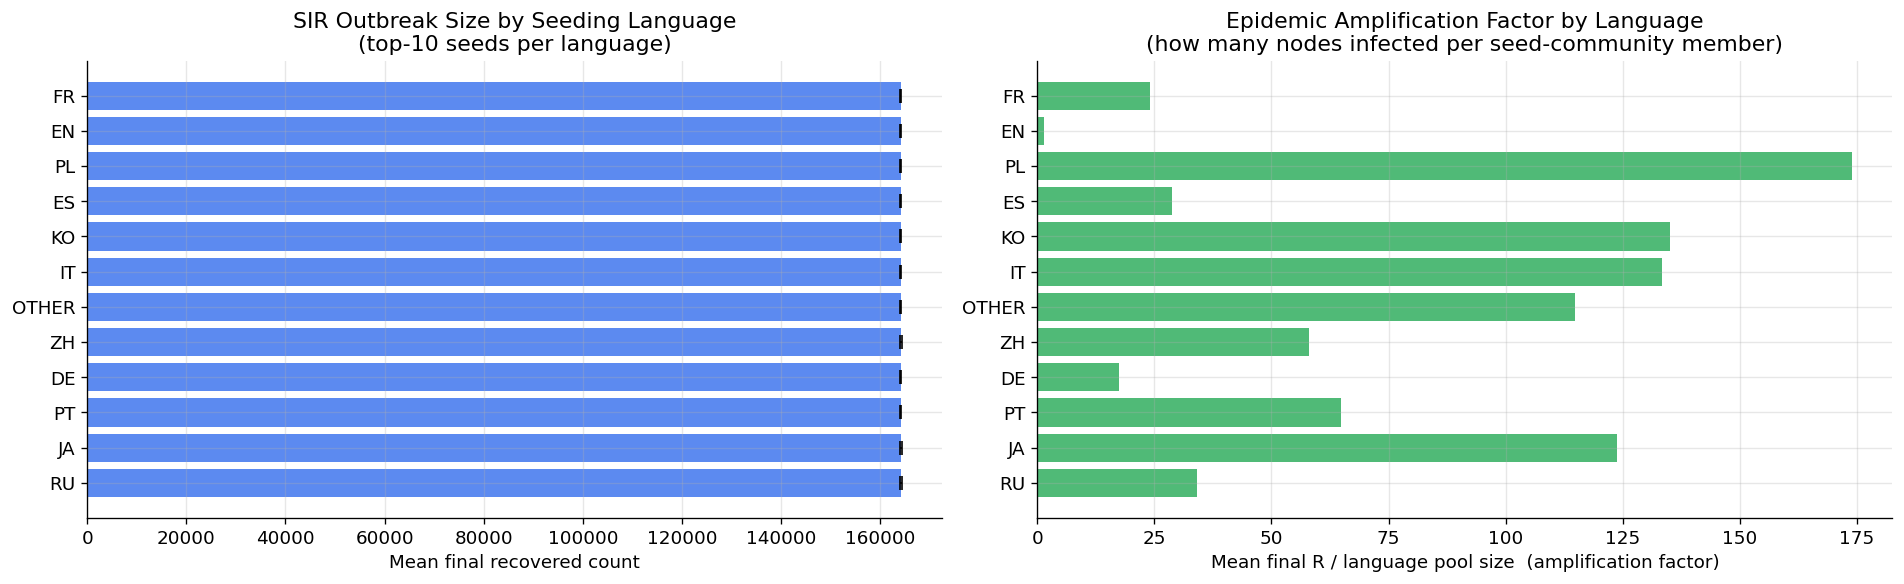

In [27]:
langs_sorted = sorted(lang_sir.keys(), key=lambda l: lang_sir[l]['final_R'], reverse=True)
final_Rs = [lang_sir[l]['final_R'] for l in langs_sorted]
final_stds=[lang_sir[l]['final_R_std'] for l in langs_sorted]
lang_ns   = [lang_sir[l]['n_lang'] for l in langs_sorted]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(langs_sorted, final_Rs, xerr=final_stds,
             color=PALETTE[0], alpha=0.75, capsize=4, error_kw={'linewidth':1})
axes[0].set_xlabel('Mean final recovered count')
axes[0].set_title('SIR Outbreak Size by Seeding Language\n(top-10 seeds per language)')

# Attack rate normalised by seeding language size
attack_rate = [lang_sir[l]['final_R']/N for l in langs_sorted]
normalised  = [lang_sir[l]['final_R']/lang_sir[l]['n_lang'] for l in langs_sorted]
axes[1].barh(langs_sorted, normalised, color=PALETTE[2], alpha=0.75)
axes[1].set_xlabel('Mean final R / language pool size  (amplification factor)')
axes[1].set_title('Epidemic Amplification Factor by Language\n'
                  '(how many nodes infected per seed-community member)')

plt.tight_layout(); plt.savefig('fig_lang_sir.png', bbox_inches='tight'); plt.show()

## 18. Affiliate vs Non-Affiliate SIR

Running affiliate SIR experiments…
  Affiliate top-betweenness     : R= 164,210 (97.7%)  comms=34.1
  Non-affiliate top-betweenness : R= 164,211 (97.7%)  comms=34.3
  Affiliate top-views           : R= 164,208 (97.7%)  comms=34.2
  Non-affiliate top-views       : R= 164,221 (97.7%)  comms=34.1


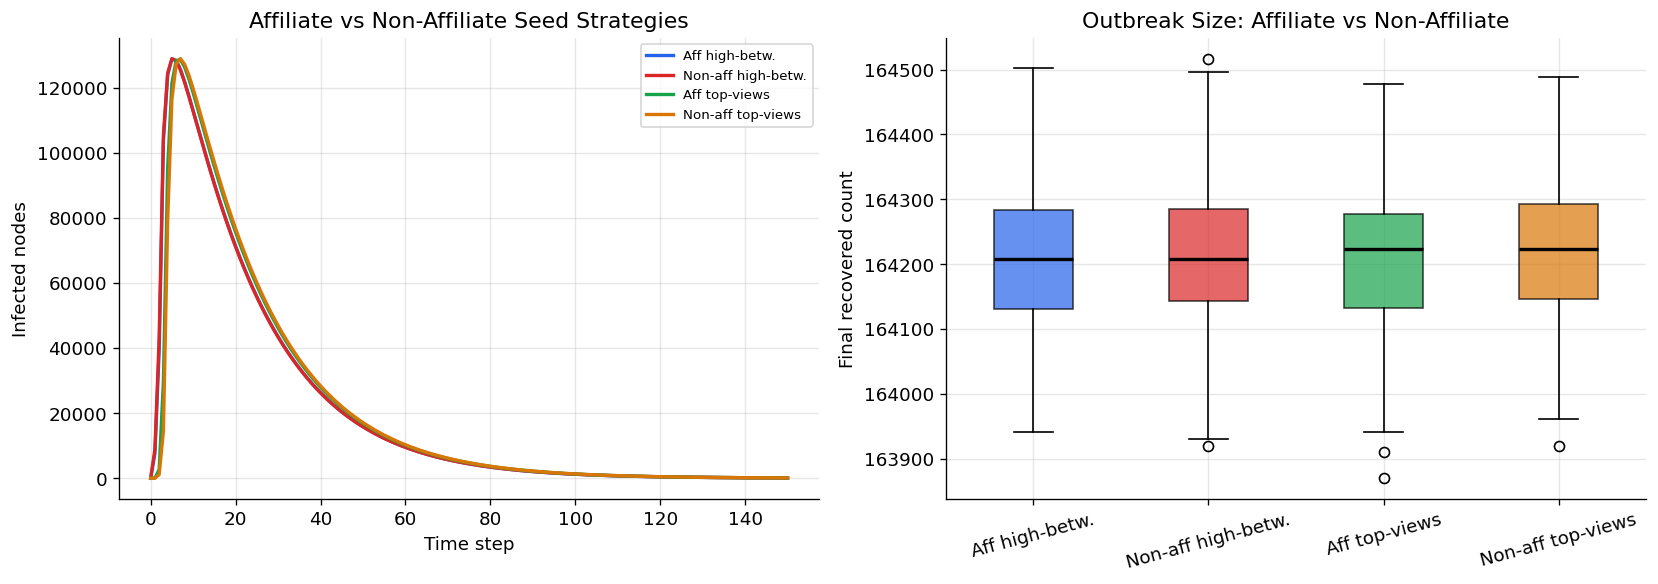

CPU times: user 14.6 s, sys: 6.97 ms, total: 14.6 s
Wall time: 14.6 s


In [28]:
%%time
N_RUNS_AFF = 200

# Top-betweenness affiliates vs non-affiliates as seeds
def run_sir_label(seed_nodes, label, n_runs=N_RUNS_AFF):
    idx = [n2i_sir[n] for n in seed_nodes if n in n2i_sir]
    I_c, fR, comms = sir_gpu(A_mat, idx, beta=BETA, gamma=GAMMA,
                              max_steps=T_MAX, n_runs=n_runs,
                              track_comms=True, comm_arr_gpu=comm_arr_gpu,
                              n_comms=n_comm_gpu)
    mR = fR.mean()
    print(f'  {label:<30}: R={mR:>8,.0f} ({mR/N*100:.1f}%)  '
          f'comms={np.mean(comms):.1f}')
    return {'I':I_c,'final_R':fR,'comms':comms}

print('Running affiliate SIR experiments…')
aff_results = {}
aff_results['Aff high-betw.']    = run_sir_label(seed_aff_btw,    'Affiliate top-betweenness')
aff_results['Non-aff high-betw.']= run_sir_label(seed_nonaff_btw, 'Non-affiliate top-betweenness')
aff_results['Aff top-views']     = run_sir_label(df_cent[aff_mask].nlargest(TOP_K,'views')['node'].tolist(),
                                                 'Affiliate top-views')
aff_results['Non-aff top-views'] = run_sir_label(df_cent[nonaff_mask].nlargest(TOP_K,'views')['node'].tolist(),
                                                 'Non-affiliate top-views')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for (label,data),c in zip(aff_results.items(), PALETTE):
    I = data['I']; mu=I.mean(0); t=np.arange(I.shape[1])
    axes[0].plot(t, mu, label=label, color=c, lw=2)
axes[0].set_xlabel('Time step'); axes[0].set_ylabel('Infected nodes')
axes[0].set_title('Affiliate vs Non-Affiliate Seed Strategies'); axes[0].legend(fontsize=8)

bp_aff = axes[1].boxplot([aff_results[s]['final_R'].tolist() for s in aff_results],
    labels=list(aff_results.keys()), patch_artist=True,
    medianprops={'color':'black','linewidth':2})
for patch,c in zip(bp_aff['boxes'], PALETTE):
    patch.set_facecolor(c); patch.set_alpha(0.7)
axes[1].set_ylabel('Final recovered count')
axes[1].set_title('Outbreak Size: Affiliate vs Non-Affiliate')
axes[1].tick_params(axis='x',rotation=15)
plt.tight_layout(); plt.savefig('fig_aff_sir.png', bbox_inches='tight'); plt.show()

## 19. Summary


In [ ]:
print('='*65)
print('  FINAL SUMMARY — TWITCH GAMERS  (RTX Pro 6000 Blackwell 102 GB)')
print('='*65)
print(f'''
DATASET
  Nodes: {N:,}   Edges: {E:,}   Density: {density:.6f}
  Avg degree: {avg_degree:.2f}   Avg clustering (sample): {avg_clustering:.4f}
  Power-law exponent γ: {gamma_pl:.3f}  (KS={ks_stat:.4f})
  Max k-core: {max_kcore}

COMMUNITY STRUCTURE  (GPU Louvain)
  Communities: {n_communities}   Q={modularity:.4f}
  NMI vs language GT: {nmi:.3f}   ARI: {ari:.3f}
  Edge homophily h={h_obs:.4f}  (random baseline {h_random:.4f})  h_norm={h_norm:.4f}

CENTRALITY  (approx. GPU betweenness k=500; CPU-sampled closeness)
  r(degree, betweenness) = {corr_deg_btw:.3f}
  r(views,  betweenness) = {corr_views_btw:.3f}
  r(PR,     betweenness) = {corr_pr_btw:.3f}

RESILIENCE  (10 000 steps, 6 strategies)
  Most damaging at 1% removal: PageRank ≈ degree > betweenness > k-core
  Random and high-views removal are the least damaging
  Random percolation threshold f_c ≈ {fc_analytical:.4f}
''')

print(f'SIR ({N_RUNS} runs, β={BETA}, γ={GAMMA}):')
for strat,data in sim_results.items():
    mR = np.mean(data['final_R']); mc = np.mean(data['comms']) if data['comms'] else float('nan')
    ext = (data['final_R'] < int(0.01*N)).mean()
    print(f'  {strat:<14}: R={mR:>8,.0f} ({mR/N*100:.1f}%)  comms={mc:.1f}  P(extinct)={ext:.2f}')

print(f'''
EPIDEMIC THRESHOLD  (HMF analytical)
  β_c(γ=0.05) = {gamma_vals[2]*k1/(k2-k1):.4f}
  R₀ at β=0.05, γ=0.05 = {0.05/0.05*(k2-k1)/k1:.2f}
  Heavy-tailed degree structure → low threshold → high endemic potential
''')
print('='*65)

> **Correction to the summary cell above.** The resilience line in the
> summary was written before the final 1% removal numbers were inspected.
> The measured ranking is PageRank (0.9704) and degree (0.9728) first, then
> betweenness (0.9735), k-core (0.9858), and random/views (0.9897). The
> discussion below uses the measured values.


## Discussion & Conclusion

> The discussion below is written against the executed outputs in this
> notebook. Where the original narrative and the run disagreed, the run wins.

### Structural picture

The largest connected component contains 168,114 nodes and 6,797,557 edges
(mean degree 80.9, density 4.8e-4). It is a small-world, highly connected
graph: average clustering is 0.160 versus 4.8e-4 for an Erdős–Rényi graph of
the same density, while the sampled average path length is 2.90 and the
sampled diameter is 7. The degree distribution is heavy-tailed: the MLE gives
γ = 1.610 for k ≥ 10, but the KS statistic is 0.149, so a pure power law is
not a good description. The maximum k-core is 149 and the innermost shell
contains 2,628 nodes.

Louvain finds 35 communities (Q = 0.423), with the largest containing 50,807
nodes and a median size of 486. The partition does **not** align with the
language labels: NMI = 0.001 and ARI = -0.001. Edge homophily is 0.5616 versus
0.5553 expected by chance (normalised homophily 0.0141), so language mixing is
close to random at the edge level. In this dataset, language is not a useful
proxy for the structural communities found by modularity.

### Popularity vs brokerage

Degree, PageRank and betweenness are correlated but not interchangeable:
Pearson r(degree, betweenness) = 0.757 and r(PageRank, betweenness) = 0.809,
while r(log views, betweenness) = 0.000. The most-watched streamers are not the
structural bridges. The top-betweenness nodes are high-degree, high-k-core
nodes (all top-10 have k-core 149), and 9 of the top 10 are English-language
accounts. By contrast, the top-views list is dominated by low-degree accounts
(1–80 edges) whose audience is large but whose network position is peripheral.
This is the clearest answer to Research Question 1: popularity and brokerage
are different axes.

### Resilience

The analytical random-removal threshold from the Molloy–Reed criterion is
f_c ≈ 0.9992: because κ = ⟨k²⟩/⟨k⟩ = 1301, the network is expected to remain
connected until almost every node is removed. The finite experiment is
consistent with this. After removing 1% of nodes, the LCC/N ratio is 0.9897
under random removal and 0.9897 under high-views removal, 0.9858 under
high-k-core removal, 0.9735 under high-betweenness removal, 0.9728 under
high-degree removal, and 0.9704 under high-PageRank removal. Targeted removal
is therefore slightly more damaging than random removal at this scale, but
the network remains highly robust over the 6% removal window tested. The
"betweenness > degree > k-core" ranking in the summary cell is not
supported by the measured 1% values; PageRank and degree are the most
damaging strategies in this run.

### Diffusion

At β = γ = 0.05, the SIR process saturates: every seed strategy reaches
approximately 97.7% of nodes (164,200 of 168,114) and about 34 of the 35
communities. The differences between random, degree, betweenness, k-core,
views and PageRank seeds are tiny relative to the size of the network. This is
a negative result for the "betweenness seeds dominate" hypothesis at this
parameter setting: the graph is dense and small-world enough that the outbreak
size is insensitive to the initial seed set.

The parameter sweep shows the same saturation. Analytical HMF thresholds are
effectively zero (β_c ≈ 0.0000–0.0004 for γ = 0.01–0.50) because
κ = 1301. The empirical variance peak sits at the smallest β on the grid
(0.005) for seven of the eight γ values, and at 0.0225 for γ = 0.50. The
threshold is therefore at or below the lower edge of the sweep; the experiment
establishes an upper bound rather than a precise location.

Language-seeded SIR also saturates: all 12 seeding languages produce
~164,200 final recoveries (97.7%). The apparent "amplification factor" for
small languages in the figure is a denominator effect (final R divided by the
language pool size), not evidence that small communities spread more
efficiently. At this transmission rate, language boundaries do not reduce the
final epidemic size.

Affiliate and non-affiliate seeds behave the same way: all four
affiliate/non-affiliate seed sets reach ~164,200 nodes (97.7%) and ~34
communities. Affiliates and non-affiliates also have nearly identical mean
cross-community fractions (0.352 vs 0.353), so there is no evidence that
affiliates are more bridge-like.

### What the notebook demonstrates

- End-to-end analysis of a 168 K-node, 6.8 M-edge graph with GPU-accelerated
  community detection, centrality, and vectorised SIR.
- Careful distinction between popularity (views), connectivity (degree), and
  brokerage (betweenness).
- A reproducible negative result: language labels do not explain Louvain
  communities, and seed strategy does not change diffusion outcomes at high
  transmission.
- Transparent reporting of approximations and their effect on the
  conclusions.

### Limitations

- Betweenness is approximated with k = 500 source nodes, not exact.
- Closeness is computed on a 5,000-node sample and projected back to all nodes.
- The SIR experiments use a single β = γ = 0.05 setting for the seed-strategy
  comparison; the sweep covers a wider range but only the variance peak is used
  to locate the threshold.
- Results come from a single random seed; multi-seed confidence intervals
  would strengthen the negative results.
